# Regime-Aware ML Swiss Equity Allocator

This notebook builds a daily Swiss equity strategy. The strategy uses stock characteristics, technical stock features, and market-regime variables to predict future stock return ranks. The prediction is later used as the expected-return input in a turnover-penalized portfolio optimizer.

The feature panel combines three blocks. JKP characteristics describe slow-moving stock-level information. Daily market data provide return, volatility, downside-risk, liquidity, and size features. SPI and cross-sectional market variables describe the current market regime.

The model date grid is daily. JKP characteristics are attached to each model date with an as-of match, using the latest available JKP observation for each stock. The age of the JKP observation is also included as a feature.

## Cell A — Setup and daily data schedule

This cell loads the raw datasets and prepares the daily model grid.

The main outputs are:

- `market_data`: cleaned daily stock panel
- `jkp_data`: cleaned lower-frequency characteristic panel
- `spi_returns`: daily SPI return series
- `price_wide`: daily stock price matrix
- `daily_ret_wide`: daily stock return matrix
- `model_schedule`: daily feature dates, matched JKP dates, JKP age, and future label dates
- `model_dates`: daily feature dates used by the model

The schedule defines the timing of the full strategy. Each model date uses information available up to that date and later receives a future return label over the next 21 trading days.

In [7]:
# =============================================================================
# CELL A — SETUP AND DAILY DATA SCHEDULE
# =============================================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 300)
pd.set_option("display.max_rows", 200)

# -----------------------------------------------------------------------------
# 1. Parameters
# -----------------------------------------------------------------------------

START_DATE = pd.Timestamp("2003-01-01")
DATA_END_DATE = pd.Timestamp("2024-04-30")
FEATURE_END_DATE = pd.Timestamp("2024-03-31")

PREDICTION_HORIZON_DAYS = 21
MODEL_EVERY_N_DAYS = 1
RETRAIN_EVERY_N_DAYS = 21
OPTIMIZE_EVERY_N_DAYS = 1

JKP_ASOF_TOLERANCE_DAYS = 120

MIN_STOCK_HISTORY_DAYS = 252
LOOKBACK_COV_DAYS = 756
MIN_COV_DAYS = 252

TOP_N = 80
MAX_WEIGHT = 0.05
MIN_WEIGHT = 0.00

FIXED_COST_ANNUAL = 0.01
TRANSACTION_COST = 0.002

RIDGE_ALPHA_GRID = [0.1, 1.0, 10.0, 100.0]
GAMMA_GRID = [1.0, 3.0, 5.0, 10.0, 20.0]
LAMBDA_TRADE_GRID = [0.0, 0.0005, 0.001, 0.002, 0.005, 0.01]

TRAIN_MIN_DAYS = 504
VALIDATION_DAYS = 126

EPS = 1e-12


# -----------------------------------------------------------------------------
# 2. Locate data folder
# -----------------------------------------------------------------------------

def existing_parent(path, levels):
    p = Path(path).resolve()
    for _ in range(levels):
        if p.parent == p:
            return p
        p = p.parent
    return p


CWD = Path.cwd().resolve()

DATA_DIR_CANDIDATES = [
    CWD / "data",
    CWD.parent / "data",
    existing_parent(CWD, 2) / "data",
    existing_parent(CWD, 3) / "data",
]

DATA_DIR = None
for candidate in DATA_DIR_CANDIDATES:
    required = [
        candidate / "market_data.parquet",
        candidate / "jkp_data.parquet",
        candidate / "spi_index.csv",
    ]
    if all(p.exists() for p in required):
        DATA_DIR = candidate
        break

if DATA_DIR is None:
    checked = "\n".join(str(x) for x in DATA_DIR_CANDIDATES)
    raise FileNotFoundError(
        "Data directory with market_data.parquet, jkp_data.parquet, and spi_index.csv was not found.\n"
        f"Checked:\n{checked}"
    )

print("DATA_DIR:", DATA_DIR)


# -----------------------------------------------------------------------------
# 3. Helpers
# -----------------------------------------------------------------------------

def title(text):
    print("\n" + "=" * 110)
    print(text)
    print("=" * 110)


def print_table(name, df, max_rows=None, index=False):
    print("\n" + "-" * 110)
    print(name)
    print("-" * 110)

    if df is None or len(df) == 0:
        print("EMPTY")
        return

    x = df.copy()
    if max_rows is not None:
        x = x.head(max_rows)

    print(x.to_string(index=index))


def panel_index_to_date_id(df, name):
    out = df.copy()

    if not isinstance(out.index, pd.MultiIndex):
        raise ValueError(f"{name}: expected MultiIndex with date and id.")

    if len(out.index.levels) < 2:
        raise ValueError(f"{name}: expected at least two index levels.")

    out.index = out.index.set_names(["date", "id"] + list(out.index.names[2:]))

    tmp = out.reset_index()
    tmp["date"] = pd.to_datetime(tmp["date"], errors="coerce")
    tmp["id"] = tmp["id"].astype("string")

    valid_id = (
        tmp["id"].notna()
        & tmp["id"].str.lower().ne("nan")
        & tmp["id"].str.strip().ne("")
    )
    valid_date = tmp["date"].notna()

    before = len(tmp)
    tmp = tmp.loc[valid_date & valid_id].copy()
    removed = before - len(tmp)

    tmp["id"] = tmp["id"].astype(str)
    tmp = tmp.sort_values(["date", "id"])

    duplicate_count = int(tmp.duplicated(["date", "id"]).sum())
    tmp = tmp.drop_duplicates(["date", "id"], keep="last")

    tmp = tmp.set_index(["date", "id"]).sort_index()

    print(
        f"{name}: removed invalid rows={removed:,}, "
        f"removed duplicate rows={duplicate_count:,}, final shape={tmp.shape}"
    )

    return tmp


def parse_spi_returns(spi_raw):
    out = spi_raw.copy()

    if "Unnamed: 0" in out.columns:
        out = out.rename(columns={"Unnamed: 0": "date"})

    if "date" not in out.columns:
        out = out.rename(columns={out.columns[0]: "date"})

    if "SPI" not in out.columns:
        value_cols = [c for c in out.columns if c != "date"]
        if len(value_cols) != 1:
            raise ValueError("SPI return column could not be identified.")
        out = out.rename(columns={value_cols[0]: "SPI"})

    out["date"] = pd.to_datetime(out["date"], format="%d/%m/%Y", errors="coerce")
    out["spi_return"] = pd.to_numeric(out["SPI"], errors="coerce")

    out = (
        out[["date", "spi_return"]]
        .dropna(subset=["date"])
        .sort_values("date")
        .drop_duplicates("date", keep="last")
        .set_index("date")
    )

    return out["spi_return"]


def build_daily_model_schedule(
    market_dates,
    jkp_dates,
    start_date,
    feature_end_date,
    prediction_horizon_days,
    every_n_days,
    min_history_days,
    jkp_tolerance_days,
):
    market_dates = pd.DatetimeIndex(market_dates).sort_values()
    jkp_dates = pd.DatetimeIndex(jkp_dates).sort_values()

    start_pos = market_dates.searchsorted(pd.Timestamp(start_date), side="left")
    start_pos = max(start_pos, int(min_history_days))

    end_pos = market_dates.searchsorted(pd.Timestamp(feature_end_date), side="right") - 1
    end_pos = min(end_pos, len(market_dates) - int(prediction_horizon_days) - 1)

    candidate_dates = market_dates[start_pos:end_pos + 1]

    if every_n_days > 1:
        candidate_dates = candidate_dates[::int(every_n_days)]

    rows = []

    for feature_date in candidate_dates:
        feature_pos = market_dates.searchsorted(feature_date, side="left")
        label_end_pos = feature_pos + int(prediction_horizon_days)

        if label_end_pos >= len(market_dates):
            continue

        label_end_date = market_dates[label_end_pos]

        jkp_pos = jkp_dates.searchsorted(feature_date, side="right") - 1
        if jkp_pos < 0:
            continue

        jkp_date = jkp_dates[jkp_pos]
        jkp_age_days = int((pd.Timestamp(feature_date) - pd.Timestamp(jkp_date)).days)

        if jkp_age_days > int(jkp_tolerance_days):
            continue

        rows.append({
            "feature_date": pd.Timestamp(feature_date),
            "jkp_date": pd.Timestamp(jkp_date),
            "jkp_age_days": jkp_age_days,
            "label_end_date": pd.Timestamp(label_end_date),
        })

    return pd.DataFrame(rows).drop_duplicates("feature_date").reset_index(drop=True)


# -----------------------------------------------------------------------------
# 4. Load raw data
# -----------------------------------------------------------------------------

title("LOAD RAW DATA")

market_data_raw = pd.read_parquet(DATA_DIR / "market_data.parquet")
jkp_data_raw = pd.read_parquet(DATA_DIR / "jkp_data.parquet")
spi_raw = pd.read_csv(DATA_DIR / "spi_index.csv")

print("market_data_raw shape:", market_data_raw.shape)
print("jkp_data_raw shape:", jkp_data_raw.shape)
print("spi_raw shape:", spi_raw.shape)

print("\nmarket_data_raw columns:", market_data_raw.columns.tolist())
print("jkp_data_raw columns:", len(jkp_data_raw.columns))
print("spi_raw columns:", spi_raw.columns.tolist())


# -----------------------------------------------------------------------------
# 5. Clean panels and benchmark
# -----------------------------------------------------------------------------

title("CLEAN PANELS")

market_data = panel_index_to_date_id(market_data_raw, "market_data")
jkp_data = panel_index_to_date_id(jkp_data_raw, "jkp_data")
spi_returns = parse_spi_returns(spi_raw)

market_data = market_data.loc[
    (market_data.index.get_level_values("date") >= START_DATE)
    & (market_data.index.get_level_values("date") <= DATA_END_DATE)
].copy()

jkp_data = jkp_data.loc[
    (jkp_data.index.get_level_values("date") >= START_DATE - pd.Timedelta(days=JKP_ASOF_TOLERANCE_DAYS + 31))
    & (jkp_data.index.get_level_values("date") <= FEATURE_END_DATE)
].copy()

spi_returns = spi_returns.loc[
    (spi_returns.index >= START_DATE)
    & (spi_returns.index <= DATA_END_DATE)
].copy()

for c in ["price", "mktcap", "liquidity"]:
    if c in market_data.columns:
        market_data[c] = pd.to_numeric(market_data[c], errors="coerce")

jkp_data = jkp_data.apply(pd.to_numeric, errors="coerce")

print("\nmarket_data date range:", market_data.index.get_level_values("date").min(), "to", market_data.index.get_level_values("date").max())
print("jkp_data date range:", jkp_data.index.get_level_values("date").min(), "to", jkp_data.index.get_level_values("date").max())
print("spi_returns date range:", spi_returns.index.min(), "to", spi_returns.index.max())

print("\nmarket_data ids:", market_data.index.get_level_values("id").nunique())
print("jkp_data ids:", jkp_data.index.get_level_values("id").nunique())


# -----------------------------------------------------------------------------
# 6. Build daily stock return matrix
# -----------------------------------------------------------------------------

title("BUILD DAILY STOCK RETURNS")

price_wide = (
    market_data["price"]
    .unstack("id")
    .sort_index()
    .replace([np.inf, -np.inf], np.nan)
)

price_wide = price_wide.where(price_wide > 0.0)

daily_ret_wide = price_wide.pct_change(fill_method=None)
daily_ret_wide = daily_ret_wide.replace([np.inf, -np.inf], np.nan)

daily_ret_long = (
    daily_ret_wide
    .stack(future_stack=True)
    .dropna()
    .rename("stock_return")
    .to_frame()
)
daily_ret_long.index.names = ["date", "id"]

print("price_wide shape:", price_wide.shape)
print("daily_ret_wide shape:", daily_ret_wide.shape)
print("daily_ret_long shape:", daily_ret_long.shape)
print("daily return date range:", daily_ret_wide.index.min(), "to", daily_ret_wide.index.max())


# -----------------------------------------------------------------------------
# 7. Daily model schedule
# -----------------------------------------------------------------------------

title("BUILD DAILY MODEL SCHEDULE")

available_market_dates = pd.DatetimeIndex(price_wide.index).sort_values()
available_jkp_dates = pd.DatetimeIndex(jkp_data.index.get_level_values("date").unique()).sort_values()

model_schedule = build_daily_model_schedule(
    market_dates=available_market_dates,
    jkp_dates=available_jkp_dates,
    start_date=START_DATE,
    feature_end_date=FEATURE_END_DATE,
    prediction_horizon_days=PREDICTION_HORIZON_DAYS,
    every_n_days=MODEL_EVERY_N_DAYS,
    min_history_days=MIN_STOCK_HISTORY_DAYS,
    jkp_tolerance_days=JKP_ASOF_TOLERANCE_DAYS,
)

model_dates = pd.DatetimeIndex(model_schedule["feature_date"])
rebalance_dates = model_dates

print("model_schedule shape:", model_schedule.shape)
print("model_dates length:", len(model_dates))
print("model_dates first/last:", model_dates.min(), model_dates.max())
print("label_end_date first/last:", model_schedule["label_end_date"].min(), model_schedule["label_end_date"].max())
print("unique JKP source dates used:", model_schedule["jkp_date"].nunique())

print_table("Model schedule head", model_schedule.head(12))
print_table("Model schedule tail", model_schedule.tail(12))

jkp_age_summary = model_schedule["jkp_age_days"].describe().to_frame()
print("\nJKP age summary in daily model schedule:")
print(jkp_age_summary.to_string())


# -----------------------------------------------------------------------------
# 8. Initial diagnostics
# -----------------------------------------------------------------------------

title("INITIAL DIAGNOSTICS")

market_obs_by_id = market_data.groupby(level="id").size()
jkp_obs_by_id = jkp_data.groupby(level="id").size()

diagnostics = pd.DataFrame({
    "metric": [
        "market rows",
        "jkp rows",
        "spi observations",
        "stock ids in market_data",
        "stock ids in jkp_data",
        "price matrix rows",
        "price matrix columns",
        "daily model dates",
        "prediction horizon days",
        "model every n days",
        "JKP as-of tolerance days",
    ],
    "value": [
        len(market_data),
        len(jkp_data),
        len(spi_returns),
        market_data.index.get_level_values("id").nunique(),
        jkp_data.index.get_level_values("id").nunique(),
        price_wide.shape[0],
        price_wide.shape[1],
        len(model_dates),
        PREDICTION_HORIZON_DAYS,
        MODEL_EVERY_N_DAYS,
        JKP_ASOF_TOLERANCE_DAYS,
    ],
})

print_table("Initial diagnostic table", diagnostics)

print("\nmarket observations per stock:")
print(market_obs_by_id.describe().to_string())

print("\nJKP observations per stock:")
print(jkp_obs_by_id.describe().to_string())

print("\nSPI return summary:")
print(spi_returns.describe().to_string())

print("\nObjects created:")
print("market_data_raw, jkp_data_raw, spi_raw")
print("market_data, jkp_data, spi_returns")
print("price_wide, daily_ret_wide, daily_ret_long")
print("model_schedule, model_dates, rebalance_dates")

DATA_DIR: <repo>/data

LOAD RAW DATA
market_data_raw shape: (1434082, 4)
jkp_data_raw shape: (130578, 153)
spi_raw shape: (9251, 2)

market_data_raw columns: ['price', 'mktcap', 'liquidity', 'sector']
jkp_data_raw columns: 153
spi_raw columns: ['Unnamed: 0', 'SPI']

CLEAN PANELS
market_data: removed invalid rows=43,449, removed duplicate rows=0, final shape=(1390633, 4)
jkp_data: removed invalid rows=47,157, removed duplicate rows=11,388, final shape=(72033, 153)

market_data date range: 2003-01-02 00:00:00 to 2024-04-30 00:00:00
jkp_data date range: 2002-08-31 00:00:00 to 2024-03-31 00:00:00
spi_returns date range: 2003-01-01 00:00:00 to 2024-04-30 00:00:00

market_data ids: 282
jkp_data ids: 285

BUILD DAILY STOCK RETURNS
price_wide shape: (5559, 282)
daily_ret_wide shape: (5559, 282)
daily_ret_long shape: (998324, 1)
daily return date range: 2003-01-02 00:00:00 to 2024-04-30 00:00:00

BUILD DAILY MODEL SCHEDULE
model_schedule shape: (5285, 4)
model_dates length: 5285
model_dates fir

## Cell B — Daily feature engineering

This cell builds the daily feature panel.

The JKP block is formed by as-of matching. For each stock and each model date, the latest available JKP characteristic vector is used if it is within the allowed age window. The panel also includes `jkp_age_days` and freshness indicators.

The technical block is computed from daily stock prices, returns, market cap, and liquidity. It contains trailing returns, realized volatility, downside volatility, Sortino ratios, drawdowns, size, liquidity level, and liquidity shocks.

The regime block is computed from daily SPI returns and the cross-section of Swiss stock returns. It contains market trend, volatility, downside risk, drawdown, breadth, dispersion, trimmed average stock return, and median stock volatility. Regime variables are transformed into causal z-scores and smoothed z-scores.

The final feature panel is `X_panel`. It contains JKP characteristics, JKP age variables, technical features, regime z-score features, and selected interaction terms.


BUILD DAILY JKP AS-OF FEATURE PANEL

--------------------------------------------------------------------------------------------------------------
JKP feature diagnostics
--------------------------------------------------------------------------------------------------------------
                          item     value
        requested JKP features      50.0
        available JKP features      50.0
missing requested JKP features       0.0
                daily JKP rows 1002356.0
               daily JKP dates    5285.0
        median stocks per date     187.0
           median JKP age days      15.0
              max JKP age days     120.0

BUILD DAILY STOCK TECHNICAL FEATURE PANEL

--------------------------------------------------------------------------------------------------------------
Technical feature diagnostics
--------------------------------------------------------------------------------------------------------------
                   item    value
 technical feature

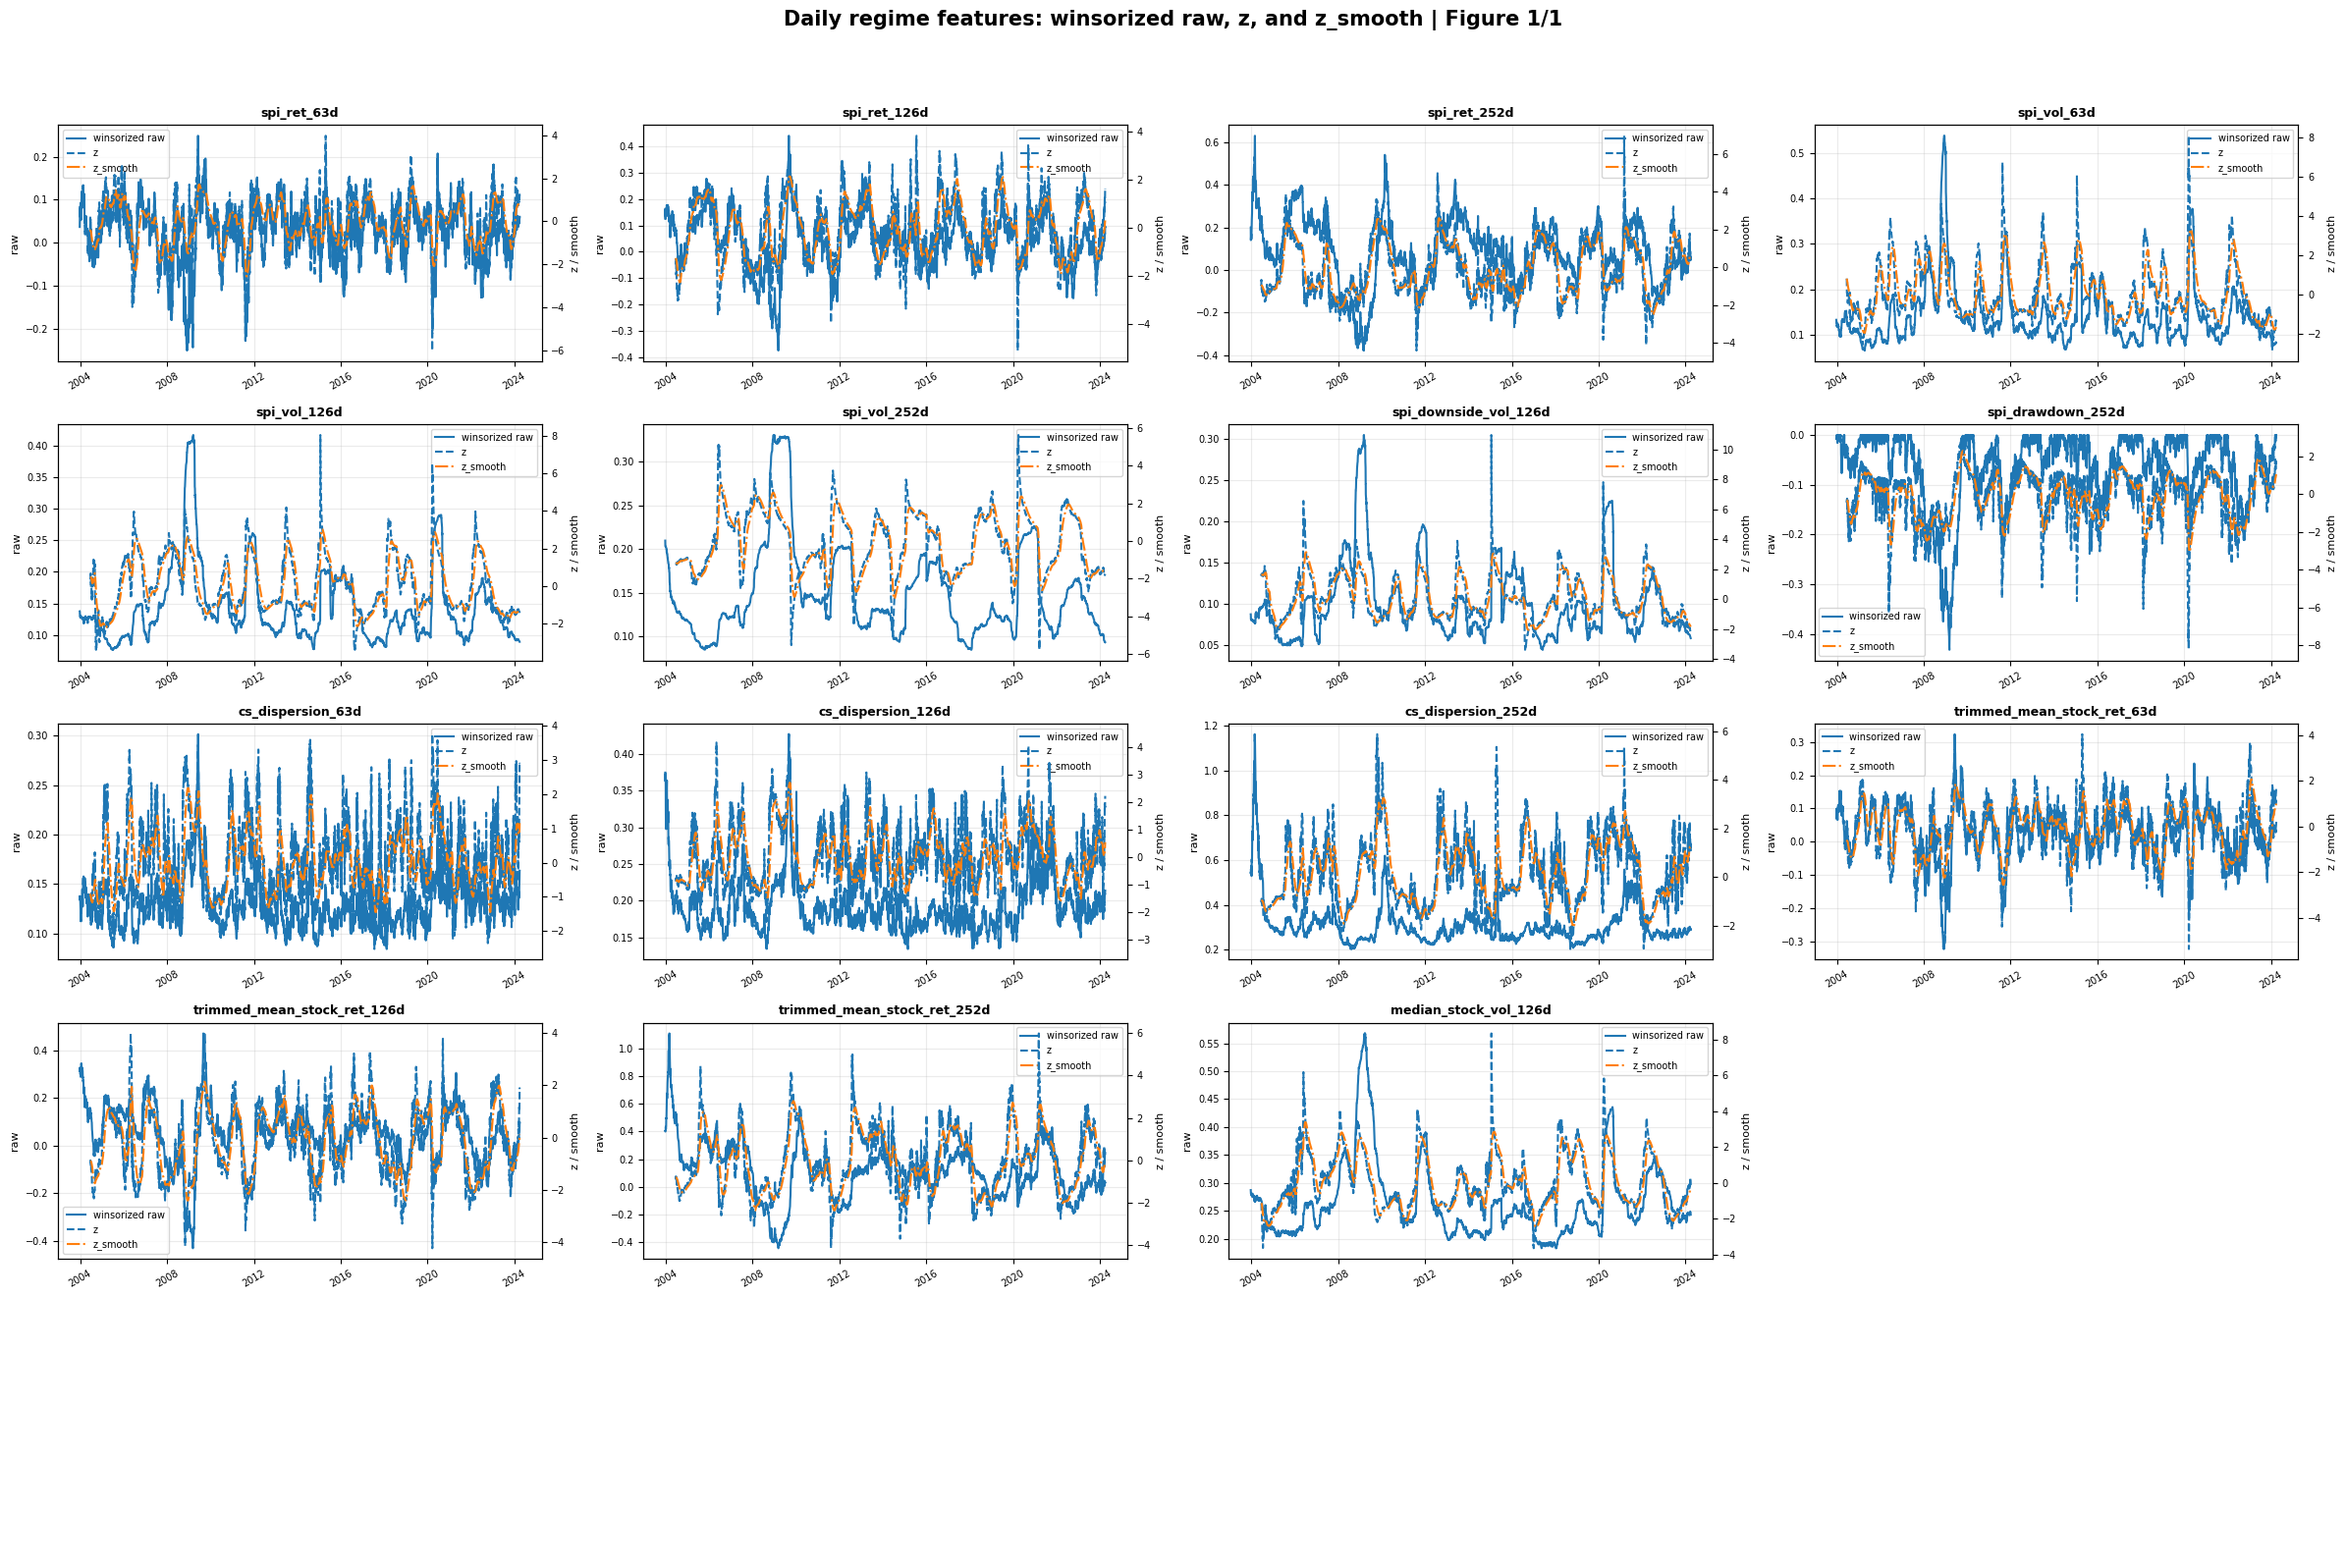


--------------------------------------------------------------------------------------------------------------
Daily JKP as-of features: raw cross-sectional medians
--------------------------------------------------------------------------------------------------------------
features: 16
figures: 1


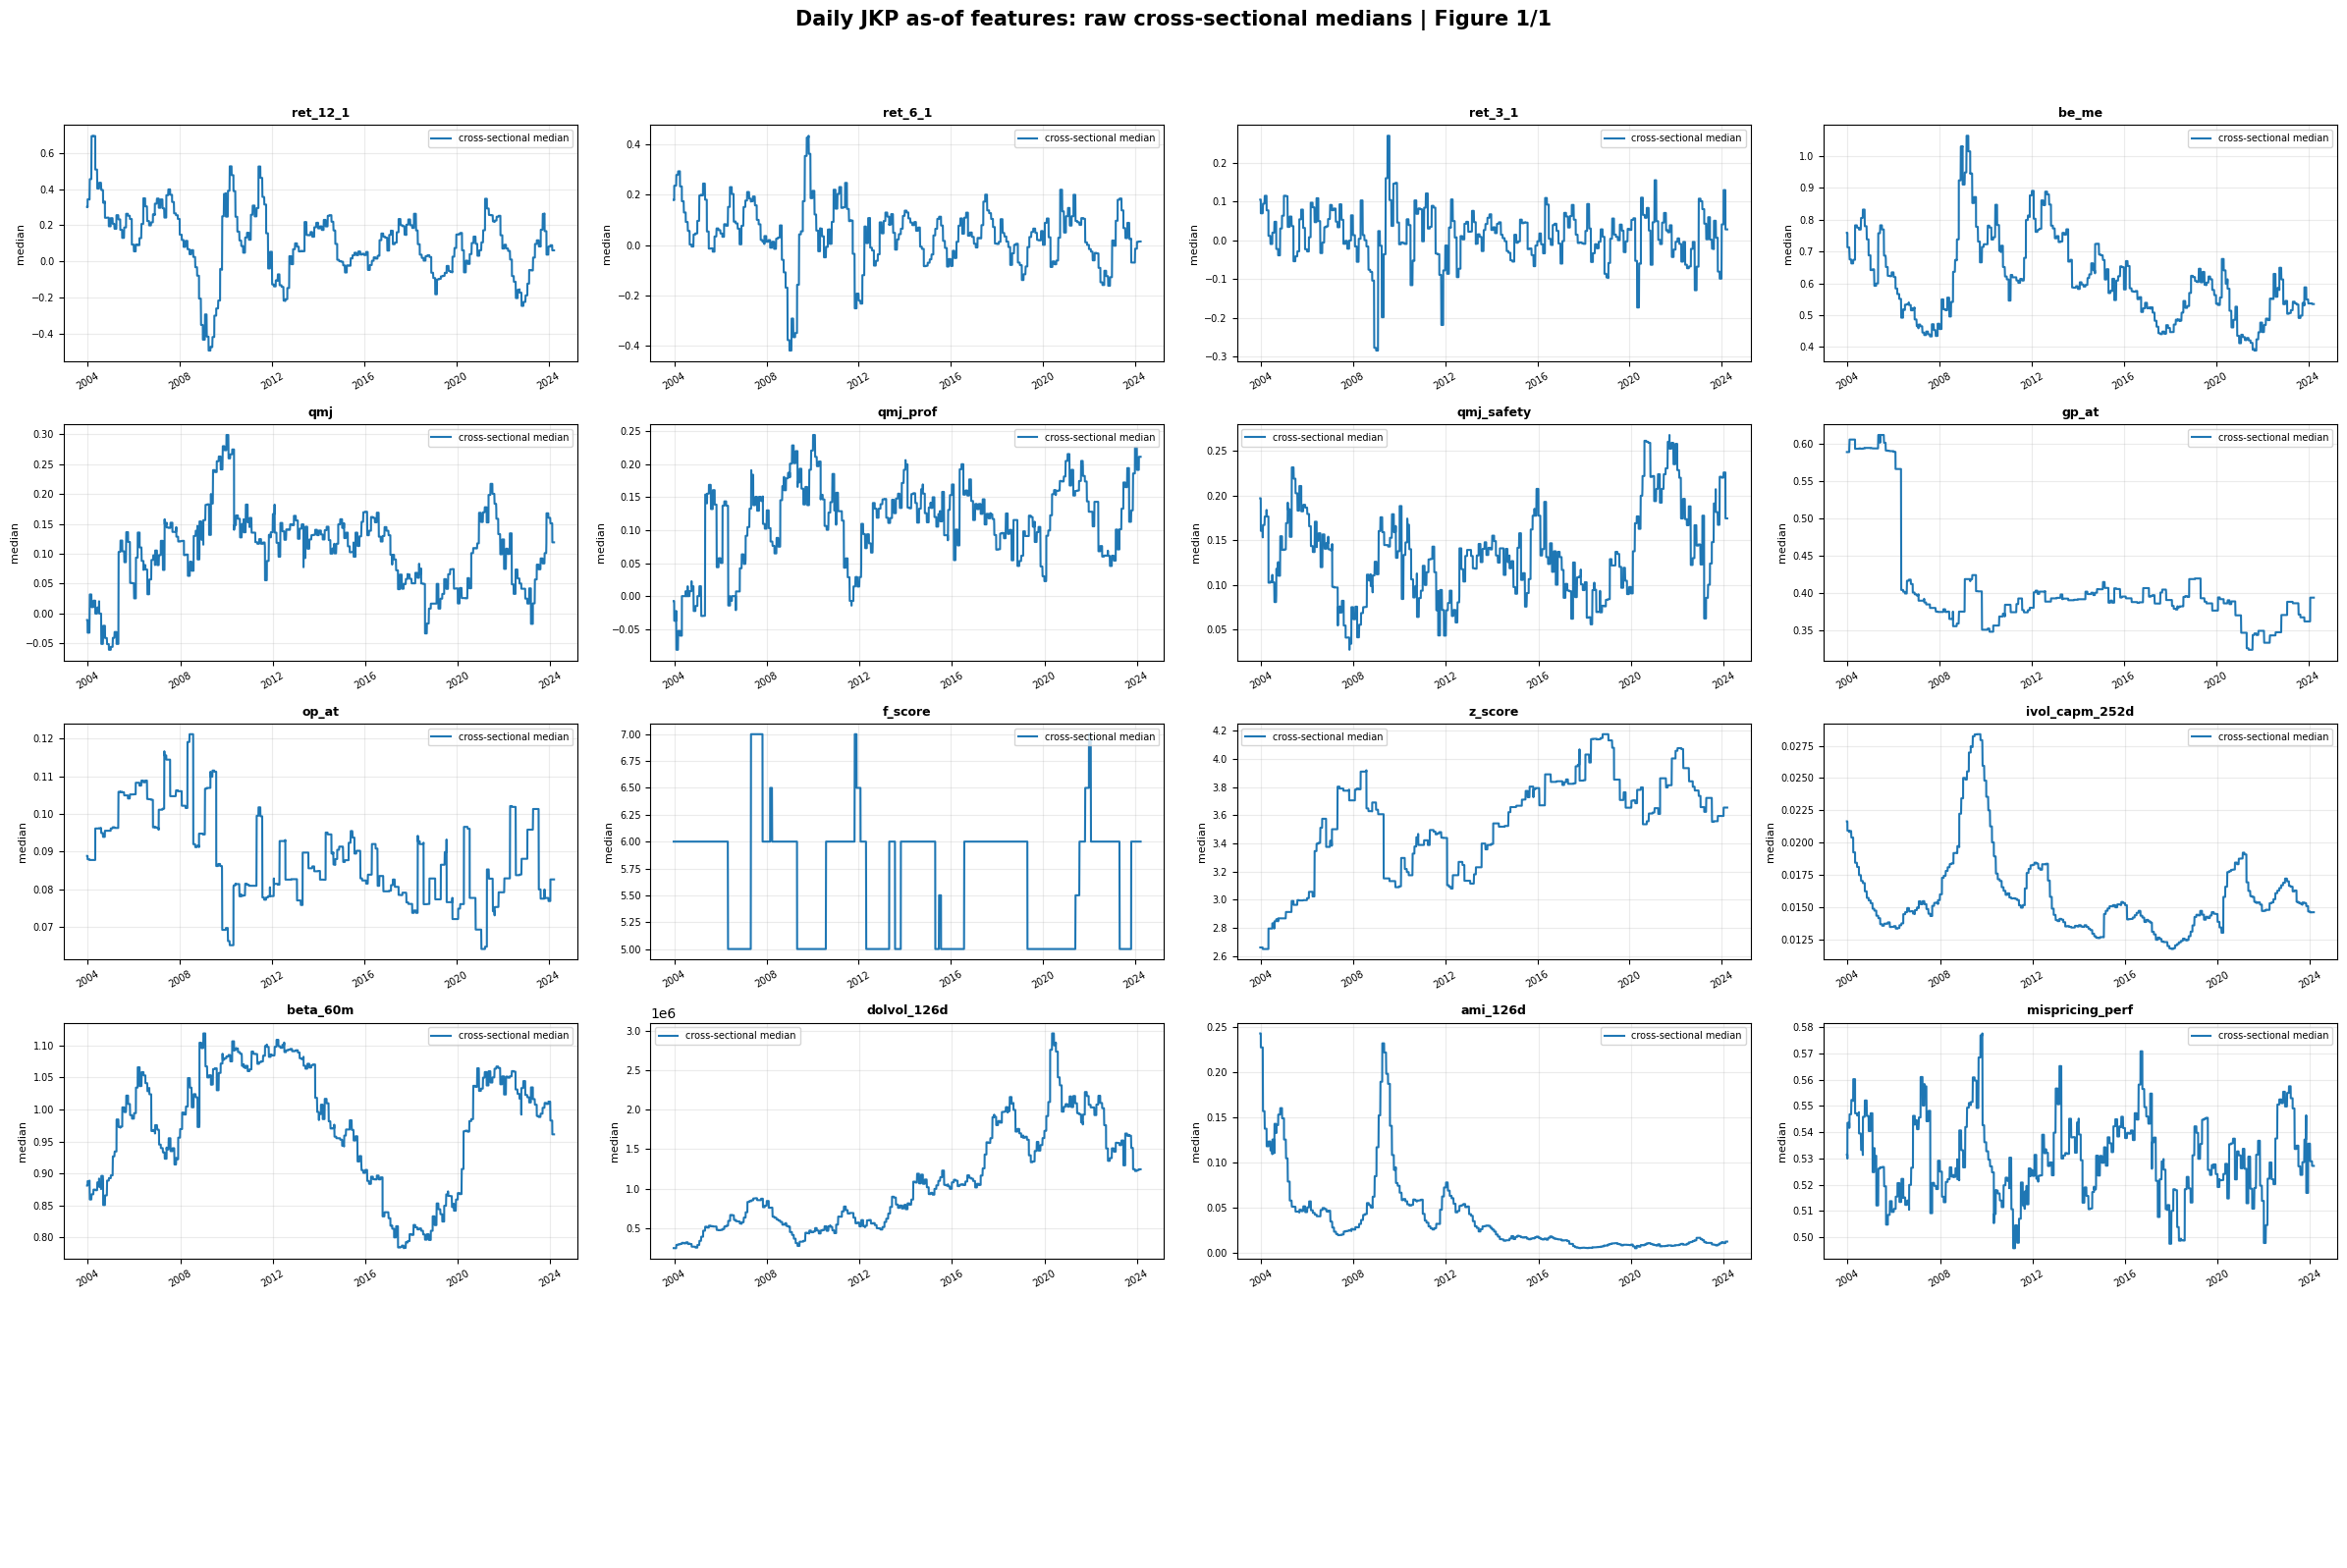


--------------------------------------------------------------------------------------------------------------
Daily technical features: raw cross-sectional medians
--------------------------------------------------------------------------------------------------------------
features: 16
figures: 1


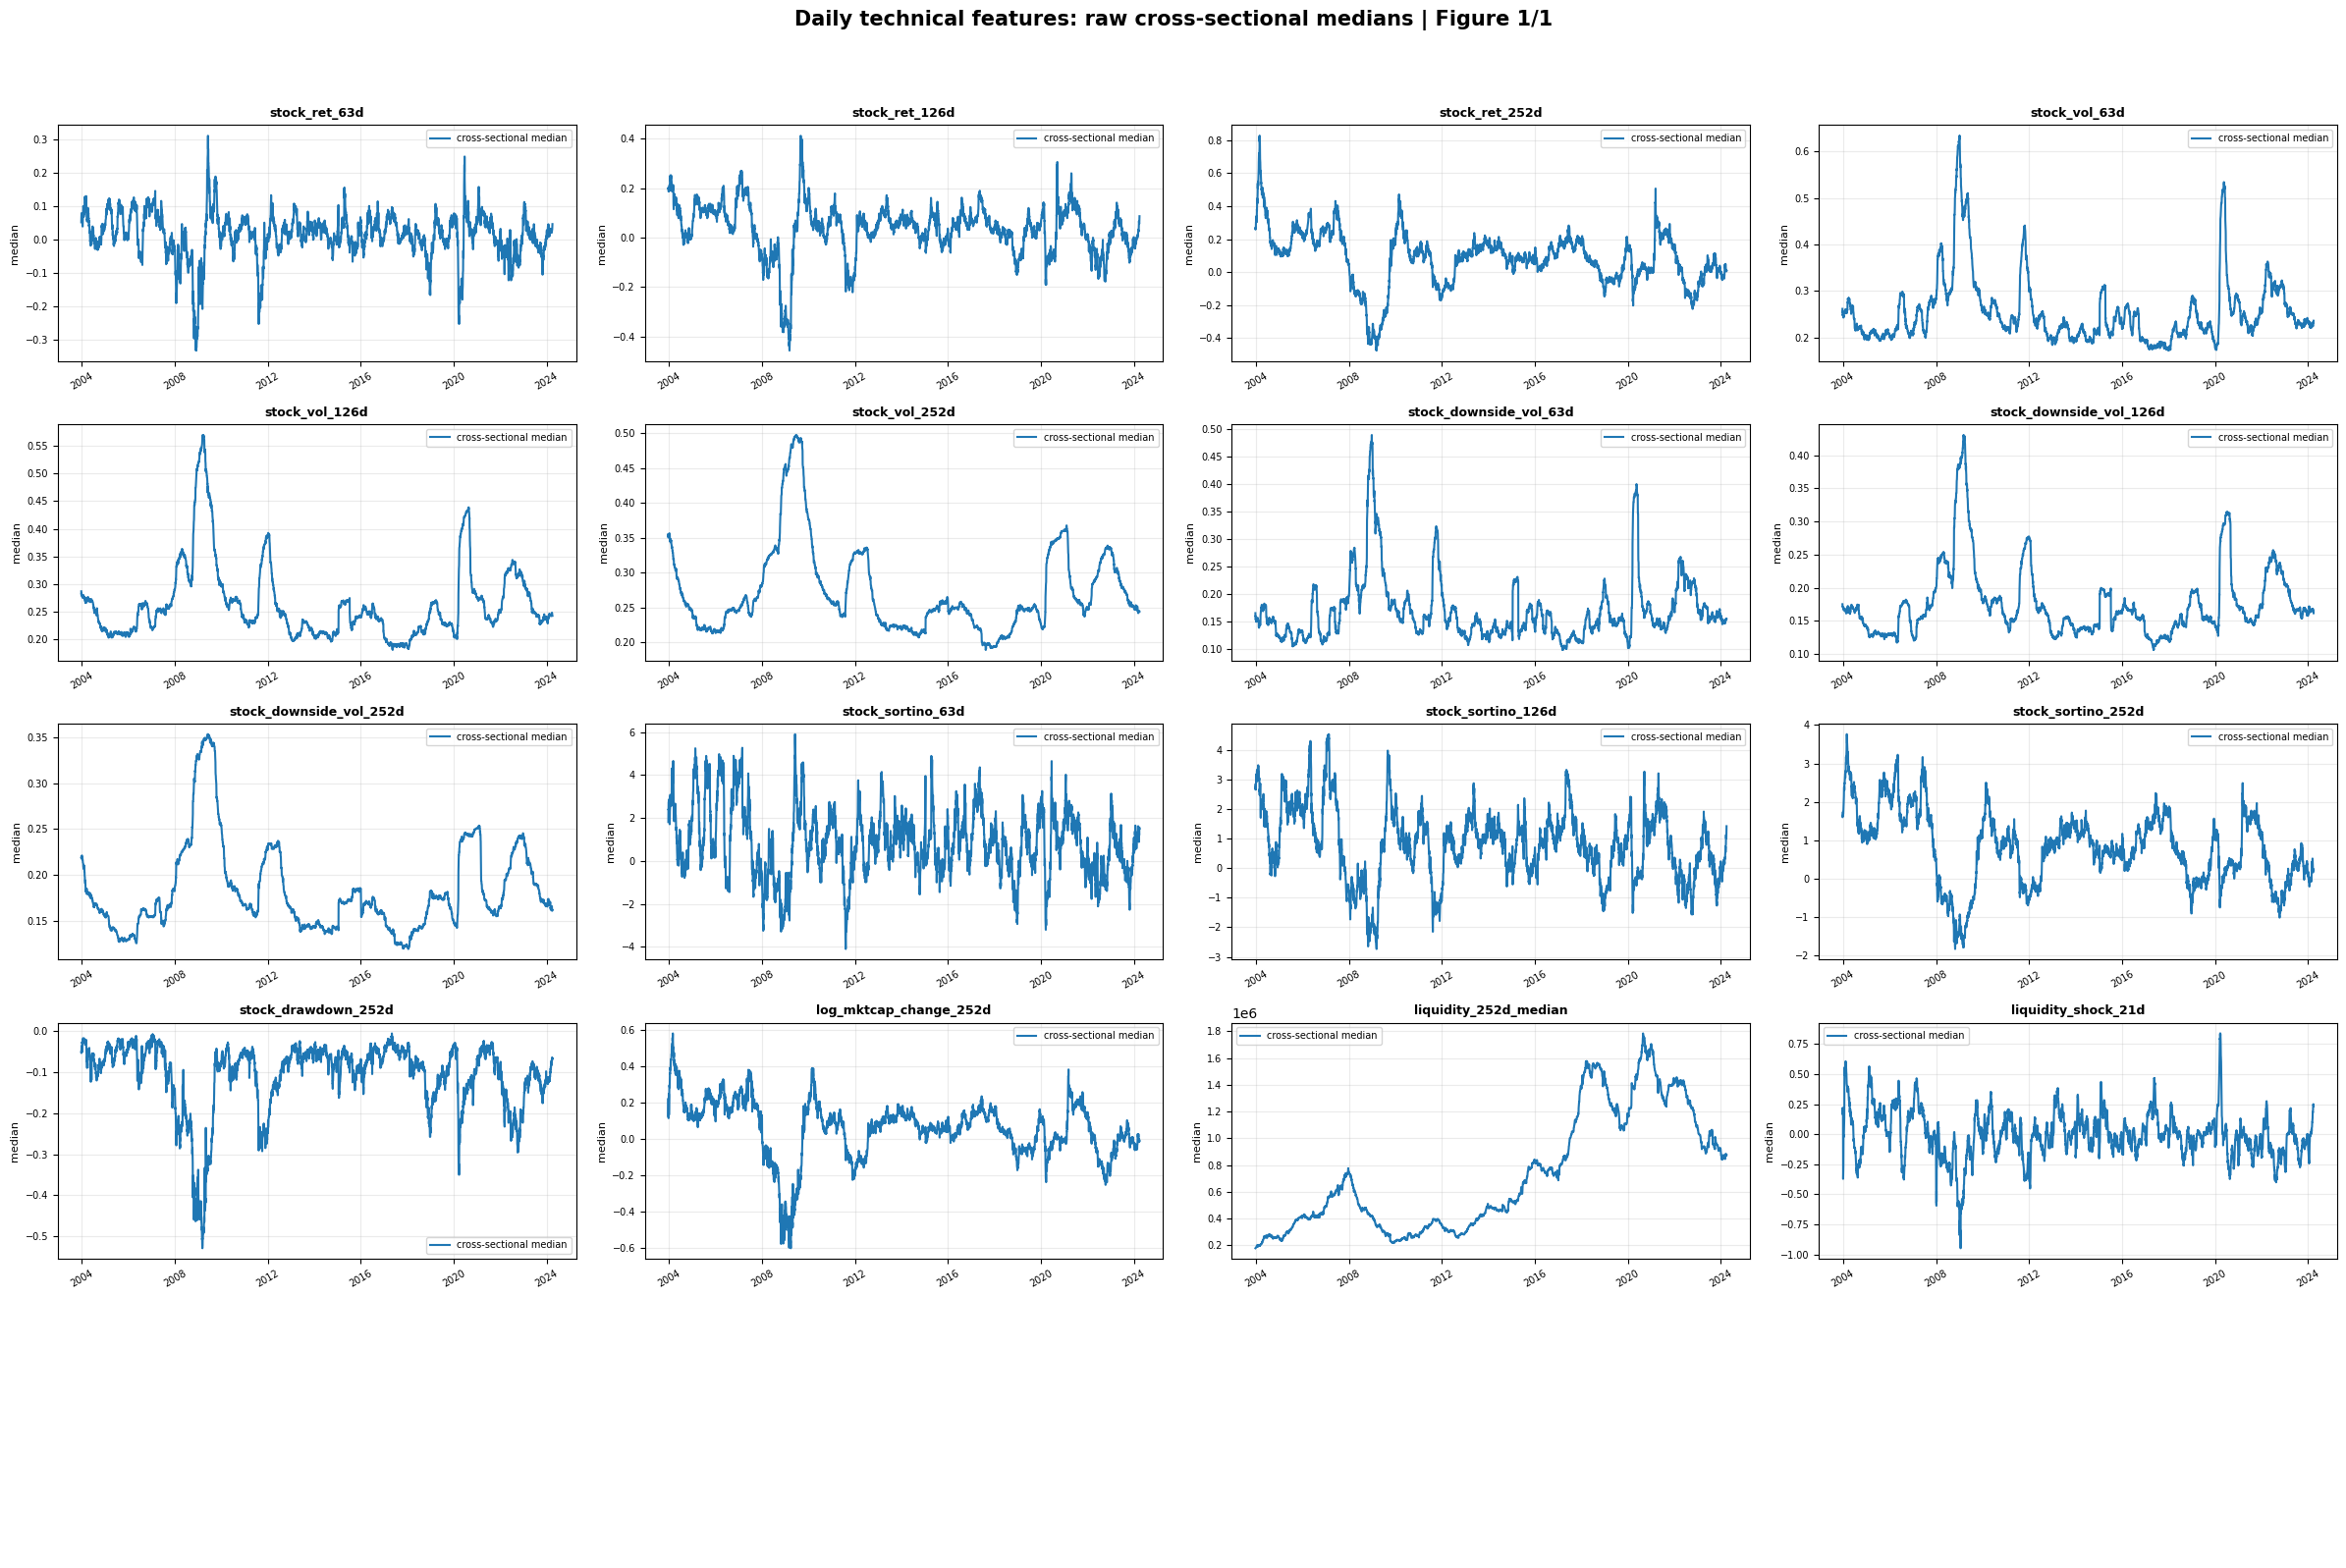

In [9]:
# =============================================================================
# CELL B — DAILY FEATURE ENGINEERING
# =============================================================================

# -----------------------------------------------------------------------------
# 1. Feature parameters
# -----------------------------------------------------------------------------

MIN_FEATURE_STOCKS_PER_DATE = 50

REGIME_STOCK_MIN_OBS_SHARE = 0.80
REGIME_CROSS_SECTIONAL_Q_LOW = 0.01
REGIME_CROSS_SECTIONAL_Q_HIGH = 0.99

REGIME_WINSOR_WINDOW = 252
REGIME_WINSOR_MIN_PERIODS = 126
REGIME_WINSOR_Q_LOW = 0.01
REGIME_WINSOR_Q_HIGH = 0.99

REGIME_Z_WINDOW = 252
REGIME_Z_MIN_PERIODS = 126
REGIME_Z_SMOOTH_HALFLIFE = 21

USE_ONLY_REGIME_Z_FEATURES_IN_MODEL = True

TECH_MIN_OBS_SHARE = 0.80

TECH_WINDOWS = {
    "21d": 21,
    "63d": 63,
    "126d": 126,
    "252d": 252,
}


# -----------------------------------------------------------------------------
# 2. Helpers
# -----------------------------------------------------------------------------

def stack_wide_feature(wide, name, dates=None):
    x = wide.copy()

    if dates is not None:
        x = x.reindex(pd.DatetimeIndex(dates))

    s = (
        x.stack(future_stack=True)
        .dropna()
        .rename(name)
    )

    s.index.names = ["date", "id"]

    return s


def causal_rolling_winsorize_series(
    s,
    window=252,
    min_periods=126,
    q_low=0.01,
    q_high=0.99,
):
    x = pd.to_numeric(s, errors="coerce")

    lo = (
        x.shift(1)
        .rolling(window=window, min_periods=min_periods)
        .quantile(q_low)
    )

    hi = (
        x.shift(1)
        .rolling(window=window, min_periods=min_periods)
        .quantile(q_high)
    )

    out = x.copy()
    valid = x.notna() & lo.notna() & hi.notna()

    out.loc[valid] = np.minimum(
        np.maximum(x.loc[valid], lo.loc[valid]),
        hi.loc[valid],
    )

    return out


def causal_time_winsorize_df(
    df,
    window=252,
    min_periods=126,
    q_low=0.01,
    q_high=0.99,
):
    out = df.copy()

    for c in out.columns:
        out[c] = causal_rolling_winsorize_series(
            out[c],
            window=window,
            min_periods=min_periods,
            q_low=q_low,
            q_high=q_high,
        )

    return out.replace([np.inf, -np.inf], np.nan)


def winsor_change_report(before, after, block_name):
    rows = []

    common_cols = [c for c in before.columns if c in after.columns]

    for c in common_cols:
        b = pd.to_numeric(before[c], errors="coerce")
        a = pd.to_numeric(after[c], errors="coerce")

        valid = b.notna() & a.notna()
        changed = valid & (b != a)

        rows.append({
            "block": block_name,
            "feature": c,
            "n_valid": int(valid.sum()),
            "n_winsorized": int(changed.sum()),
            "winsorized_share": float(changed.mean()) if len(changed) else np.nan,
        })

    return (
        pd.DataFrame(rows)
        .sort_values(["n_winsorized", "feature"], ascending=[False, True])
        .reset_index(drop=True)
    )


def causal_rolling_zscore(s, window=252, min_periods=126, eps=1e-12):
    x = pd.to_numeric(s, errors="coerce")

    mu = (
        x.shift(1)
        .rolling(window=window, min_periods=min_periods)
        .mean()
    )

    sd = (
        x.shift(1)
        .rolling(window=window, min_periods=min_periods)
        .std(ddof=0)
    )

    return (x - mu) / (sd + eps)


def wide_period_return_from_returns(ret_wide, window, min_obs_share=0.80):
    min_obs = int(np.ceil(min_obs_share * window))

    safe_ret = ret_wide.where(ret_wide > -0.999999)
    log_ret = np.log1p(safe_ret)

    obs_count = log_ret.notna().rolling(window=window, min_periods=1).sum()
    rolling_log_sum = log_ret.rolling(window=window, min_periods=min_obs).sum()

    out = np.expm1(rolling_log_sum)
    out = out.where(obs_count >= min_obs)

    return out.replace([np.inf, -np.inf], np.nan)


def wide_realized_vol(ret_wide, window, min_obs_share=0.80):
    min_obs = int(np.ceil(min_obs_share * window))

    out = (
        ret_wide
        .rolling(window=window, min_periods=min_obs)
        .std(ddof=0)
        * np.sqrt(252.0)
    )

    return out.replace([np.inf, -np.inf], np.nan)


def wide_downside_vol(ret_wide, window, min_obs_share=0.80):
    min_obs = int(np.ceil(min_obs_share * window))
    down_sq = ret_wide.clip(upper=0.0).pow(2)

    out = (
        down_sq
        .rolling(window=window, min_periods=min_obs)
        .mean()
        .pow(0.5)
        * np.sqrt(252.0)
    )

    return out.replace([np.inf, -np.inf], np.nan)


def wide_sortino(ret_wide, window, min_obs_share=0.80):
    min_obs = int(np.ceil(min_obs_share * window))

    avg = (
        ret_wide
        .rolling(window=window, min_periods=min_obs)
        .mean()
        * 252.0
    )

    down = wide_downside_vol(ret_wide, window, min_obs_share=min_obs_share)

    out = avg / (down + EPS)

    return out.replace([np.inf, -np.inf], np.nan)


def wide_drawdown_from_price(price_wide, ret_wide, window, min_obs_share=0.80):
    min_obs = int(np.ceil(min_obs_share * window))

    obs_count = ret_wide.notna().rolling(window=window, min_periods=1).sum()
    roll_max = price_wide.rolling(window=window, min_periods=min_obs).max()

    out = price_wide / (roll_max + EPS) - 1.0
    out = out.where(obs_count >= min_obs)

    return out.replace([np.inf, -np.inf], np.nan)


def cross_sectional_clip_wide(df, q_low=0.01, q_high=0.99):
    lo = df.quantile(q_low, axis=1)
    hi = df.quantile(q_high, axis=1)

    return df.clip(lower=lo, upper=hi, axis=0)


def stock_count_by_date(panel):
    return panel.groupby(level="date").size()


def available_features(features, df):
    return [c for c in features if c in df.columns]


def panel_feature_median_timeseries(panel, features):
    cols = available_features(features, panel)

    if not cols:
        return pd.DataFrame()

    out = panel[cols].groupby(level="date").median()
    out.index = pd.DatetimeIndex(out.index)

    return out.sort_index()


def filter_date_index_for_plot(df):
    out = df.copy()
    idx = pd.DatetimeIndex(out.index)

    mask = pd.Series(True, index=idx)

    if PLOT_START_DATE is not None:
        mask &= idx >= pd.Timestamp(PLOT_START_DATE)

    if PLOT_END_DATE is not None:
        mask &= idx <= pd.Timestamp(PLOT_END_DATE)

    return out.loc[mask.to_numpy()].copy()


# -----------------------------------------------------------------------------
# 3. Daily JKP as-of feature panel
# -----------------------------------------------------------------------------

title("BUILD DAILY JKP AS-OF FEATURE PANEL")

JKP_FEATURES_REQUESTED = [
    "ret_1_0", "ret_3_1", "ret_6_1", "ret_9_1", "ret_12_1", "ret_12_7",
    "resff3_6_1", "resff3_12_1",

    "be_me", "debt_me", "at_me", "ni_me", "fcf_me", "div12m_me",
    "ebitda_mev", "sale_me", "ocf_me", "netdebt_me",

    "qmj", "qmj_prof", "qmj_growth", "qmj_safety",
    "gp_at", "op_at", "cop_at", "niq_at", "niq_be",
    "f_score", "o_score", "z_score",

    "at_gr1", "sale_gr1", "sale_gr3", "inv_gr1", "inv_gr1a",
    "oaccruals_at", "taccruals_at", "noa_at",

    "rvol_21d", "ivol_capm_21d", "ivol_capm_252d",
    "beta_60m", "beta_dimson_21d", "betadown_252d",
    "dolvol_126d", "ami_126d", "bidaskhl_21d", "zero_trades_126d",

    "mispricing_perf", "mispricing_mgmt",
]

JKP_FEATURES = [c for c in JKP_FEATURES_REQUESTED if c in jkp_data.columns]
JKP_MISSING = [c for c in JKP_FEATURES_REQUESTED if c not in jkp_data.columns]

jkp_base = jkp_data[JKP_FEATURES].copy()
jkp_base = jkp_base.replace([np.inf, -np.inf], np.nan)

target_dates = pd.DataFrame({"date": model_dates})
jkp_reset = jkp_base.reset_index().sort_values(["id", "date"])
jkp_reset["jkp_source_date"] = jkp_reset["date"]

asof_parts = []

for sid, g in jkp_reset.groupby("id", sort=False):
    target = target_dates.copy()
    target["id"] = sid

    merged = pd.merge_asof(
        target.sort_values("date"),
        g.sort_values("date"),
        on="date",
        by="id",
        direction="backward",
        tolerance=pd.Timedelta(days=JKP_ASOF_TOLERANCE_DAYS),
    )

    asof_parts.append(merged)

jkp_daily = pd.concat(asof_parts, axis=0, ignore_index=True, sort=False)

jkp_daily["jkp_age_days"] = (
    jkp_daily["date"] - jkp_daily["jkp_source_date"]
).dt.days

jkp_daily["jkp_is_fresh_30d"] = jkp_daily["jkp_age_days"].le(30).astype(float)
jkp_daily["jkp_is_fresh_60d"] = jkp_daily["jkp_age_days"].le(60).astype(float)
jkp_daily["jkp_is_fresh_90d"] = jkp_daily["jkp_age_days"].le(90).astype(float)

jkp_daily = jkp_daily.dropna(subset=["jkp_source_date"]).copy()

jkp_features_d_raw = (
    jkp_daily
    .set_index(["date", "id"])[JKP_FEATURES]
    .sort_index()
    .replace([np.inf, -np.inf], np.nan)
)

jkp_age_features_d = (
    jkp_daily
    .set_index(["date", "id"])[
        ["jkp_age_days", "jkp_is_fresh_30d", "jkp_is_fresh_60d", "jkp_is_fresh_90d"]
    ]
    .sort_index()
    .replace([np.inf, -np.inf], np.nan)
)

jkp_features_d = jkp_features_d_raw.join(jkp_age_features_d, how="left")
jkp_features_d = jkp_features_d.replace([np.inf, -np.inf], np.nan)

jkp_feature_diagnostics = pd.DataFrame({
    "item": [
        "requested JKP features",
        "available JKP features",
        "missing requested JKP features",
        "daily JKP rows",
        "daily JKP dates",
        "median stocks per date",
        "median JKP age days",
        "max JKP age days",
    ],
    "value": [
        len(JKP_FEATURES_REQUESTED),
        len(JKP_FEATURES),
        len(JKP_MISSING),
        len(jkp_features_d),
        jkp_features_d.index.get_level_values("date").nunique(),
        stock_count_by_date(jkp_features_d).median(),
        float(jkp_age_features_d["jkp_age_days"].median()),
        float(jkp_age_features_d["jkp_age_days"].max()),
    ],
})

print_table("JKP feature diagnostics", jkp_feature_diagnostics)

if JKP_MISSING:
    print("\nMissing requested JKP features:")
    print(pd.Series(JKP_MISSING).to_string(index=False))


# -----------------------------------------------------------------------------
# 4. Daily stock-level technical feature panel
# -----------------------------------------------------------------------------

title("BUILD DAILY STOCK TECHNICAL FEATURE PANEL")

mktcap_wide = (
    market_data["mktcap"]
    .unstack("id")
    .sort_index()
    .replace([np.inf, -np.inf], np.nan)
)

liquidity_wide = (
    market_data["liquidity"]
    .unstack("id")
    .sort_index()
    .replace([np.inf, -np.inf], np.nan)
)

technical_series = []

for label, window in TECH_WINDOWS.items():
    stock_ret = wide_period_return_from_returns(
        ret_wide=daily_ret_wide,
        window=window,
        min_obs_share=TECH_MIN_OBS_SHARE,
    )
    technical_series.append(stack_wide_feature(stock_ret, f"stock_ret_{label}", dates=model_dates))

    stock_vol = wide_realized_vol(
        daily_ret_wide,
        window=window,
        min_obs_share=TECH_MIN_OBS_SHARE,
    )
    technical_series.append(stack_wide_feature(stock_vol, f"stock_vol_{label}", dates=model_dates))

    stock_downside = wide_downside_vol(
        daily_ret_wide,
        window=window,
        min_obs_share=TECH_MIN_OBS_SHARE,
    )
    technical_series.append(stack_wide_feature(stock_downside, f"stock_downside_vol_{label}", dates=model_dates))

    stock_sortino = wide_sortino(
        daily_ret_wide,
        window=window,
        min_obs_share=TECH_MIN_OBS_SHARE,
    )
    technical_series.append(stack_wide_feature(stock_sortino, f"stock_sortino_{label}", dates=model_dates))

    stock_drawdown = wide_drawdown_from_price(
        price_wide=price_wide,
        ret_wide=daily_ret_wide,
        window=window,
        min_obs_share=TECH_MIN_OBS_SHARE,
    )
    technical_series.append(stack_wide_feature(stock_drawdown, f"stock_drawdown_{label}", dates=model_dates))

log_mktcap = np.log(mktcap_wide.where(mktcap_wide > 0.0))
log_mktcap_change_252d = log_mktcap - log_mktcap.shift(252)

technical_series.append(
    stack_wide_feature(
        log_mktcap_change_252d,
        "log_mktcap_change_252d",
        dates=model_dates,
    )
)

liq_21 = liquidity_wide.rolling(window=21, min_periods=17).median()
liq_252 = liquidity_wide.rolling(window=252, min_periods=202).median()
liquidity_shock_21d = np.log((liq_21 + EPS) / (liq_252 + EPS))

technical_series.append(stack_wide_feature(liq_252, "liquidity_252d_median", dates=model_dates))
technical_series.append(stack_wide_feature(liquidity_shock_21d, "liquidity_shock_21d", dates=model_dates))

technical_features_d_raw = (
    pd.concat(technical_series, axis=1)
    .sort_index()
    .replace([np.inf, -np.inf], np.nan)
)

technical_features_d = technical_features_d_raw.copy()

technical_feature_diagnostics = pd.DataFrame({
    "item": [
        "technical feature rows",
        "technical feature dates",
        "technical features",
        "median stocks per date",
    ],
    "value": [
        len(technical_features_d),
        technical_features_d.index.get_level_values("date").nunique(),
        technical_features_d.shape[1],
        stock_count_by_date(technical_features_d).median(),
    ],
})

print_table("Technical feature diagnostics", technical_feature_diagnostics)


# -----------------------------------------------------------------------------
# 5. Daily SPI regime and Swiss market-state features
# -----------------------------------------------------------------------------

title("BUILD DAILY SPI REGIME AND SWISS MARKET-STATE FEATURES")

market_dates = pd.DatetimeIndex(price_wide.index).sort_values()
spi_trading = spi_returns.reindex(market_dates).fillna(0.0)

regime_raw = pd.DataFrame(index=market_dates)

spi_wealth = (1.0 + spi_trading).cumprod()

for label, window in [("63d", 63), ("126d", 126), ("252d", 252)]:
    min_obs = int(np.ceil(REGIME_STOCK_MIN_OBS_SHARE * window))

    regime_raw[f"spi_ret_{label}"] = spi_wealth / spi_wealth.shift(window) - 1.0

    regime_raw[f"spi_vol_{label}"] = (
        spi_trading
        .rolling(window=window, min_periods=min_obs)
        .std(ddof=0)
        * np.sqrt(252.0)
    )

    spi_down_sq = spi_trading.clip(upper=0.0).pow(2)

    regime_raw[f"spi_downside_vol_{label}"] = (
        spi_down_sq
        .rolling(window=window, min_periods=min_obs)
        .mean()
        .pow(0.5)
        * np.sqrt(252.0)
    )

    stock_period_ret = wide_period_return_from_returns(
        ret_wide=daily_ret_wide,
        window=window,
        min_obs_share=REGIME_STOCK_MIN_OBS_SHARE,
    )

    stock_period_ret = cross_sectional_clip_wide(
        stock_period_ret,
        q_low=REGIME_CROSS_SECTIONAL_Q_LOW,
        q_high=REGIME_CROSS_SECTIONAL_Q_HIGH,
    )

    regime_raw[f"cs_dispersion_{label}"] = stock_period_ret.std(axis=1, skipna=True, ddof=0)
    regime_raw[f"trimmed_mean_stock_ret_{label}"] = stock_period_ret.mean(axis=1, skipna=True)

    stock_vol = wide_realized_vol(
        daily_ret_wide,
        window=window,
        min_obs_share=REGIME_STOCK_MIN_OBS_SHARE,
    )

    stock_vol = cross_sectional_clip_wide(
        stock_vol,
        q_low=REGIME_CROSS_SECTIONAL_Q_LOW,
        q_high=REGIME_CROSS_SECTIONAL_Q_HIGH,
    )

    regime_raw[f"median_stock_vol_{label}"] = stock_vol.median(axis=1, skipna=True)

spi_roll_max = spi_wealth.rolling(window=252, min_periods=202).max()
regime_raw["spi_drawdown_252d"] = spi_wealth / (spi_roll_max + EPS) - 1.0

regime_raw = (
    regime_raw
    .reindex(model_dates)
    .replace([np.inf, -np.inf], np.nan)
    .dropna(how="all")
)

regime_winsor = causal_time_winsorize_df(
    regime_raw,
    window=REGIME_WINSOR_WINDOW,
    min_periods=REGIME_WINSOR_MIN_PERIODS,
    q_low=REGIME_WINSOR_Q_LOW,
    q_high=REGIME_WINSOR_Q_HIGH,
)

regime_winsor_report = winsor_change_report(
    before=regime_raw,
    after=regime_winsor,
    block_name="regime",
)

regime_features_d = regime_winsor.copy()

for c in regime_winsor.columns:
    z_col = f"{c}_z"
    smooth_col = f"{c}_z_smooth"

    regime_features_d[z_col] = causal_rolling_zscore(
        regime_winsor[c],
        window=REGIME_Z_WINDOW,
        min_periods=REGIME_Z_MIN_PERIODS,
        eps=EPS,
    )

    regime_features_d[smooth_col] = (
        regime_features_d[z_col]
        .ewm(halflife=REGIME_Z_SMOOTH_HALFLIFE, adjust=False, min_periods=1)
        .mean()
    )

regime_features_d = regime_features_d.replace([np.inf, -np.inf], np.nan)

regime_feature_diagnostics = pd.DataFrame({
    "item": [
        "regime feature dates",
        "raw regime features",
        "total regime features",
        "first regime date",
        "last regime date",
        "winsorization window",
        "winsorization min periods",
        "winsorization lower quantile",
        "winsorization upper quantile",
        "z-score window",
        "z-score min periods",
        "z-score smooth halflife",
    ],
    "value": [
        len(regime_features_d),
        len(regime_raw.columns),
        len(regime_features_d.columns),
        regime_features_d.index.min(),
        regime_features_d.index.max(),
        REGIME_WINSOR_WINDOW,
        REGIME_WINSOR_MIN_PERIODS,
        REGIME_WINSOR_Q_LOW,
        REGIME_WINSOR_Q_HIGH,
        REGIME_Z_WINDOW,
        REGIME_Z_MIN_PERIODS,
        REGIME_Z_SMOOTH_HALFLIFE,
    ],
})

print_table("Regime feature diagnostics", regime_feature_diagnostics)
print_table("Regime causal winsorization report — largest changes", regime_winsor_report.head(20))


# -----------------------------------------------------------------------------
# 6. Merge feature blocks
# -----------------------------------------------------------------------------

title("MERGE DAILY FEATURE BLOCKS")

base_panel = jkp_features_d.join(technical_features_d, how="inner")
base_panel = base_panel.replace([np.inf, -np.inf], np.nan)

if USE_ONLY_REGIME_Z_FEATURES_IN_MODEL:
    regime_model_cols = [
        c for c in regime_features_d.columns
        if c.endswith("_z") or c.endswith("_z_smooth")
    ]
else:
    regime_model_cols = list(regime_features_d.columns)

regime_model_features_d = regime_features_d[regime_model_cols].copy()

for c in regime_model_features_d.columns:
    mapper = regime_model_features_d[c]
    base_panel[c] = base_panel.index.get_level_values("date").map(mapper)

base_panel = base_panel.replace([np.inf, -np.inf], np.nan)

print("base_panel shape before interactions:", base_panel.shape)
print("base_panel date range:", base_panel.index.get_level_values("date").min(), "to", base_panel.index.get_level_values("date").max())
print("base_panel unique dates:", base_panel.index.get_level_values("date").nunique())


# -----------------------------------------------------------------------------
# 7. Regime interaction features
# -----------------------------------------------------------------------------

title("ADD REGIME INTERACTION FEATURES")

interaction_specs = [
    ("ret_12_1", "spi_ret_126d_z_smooth"),
    ("ret_6_1", "spi_ret_126d_z_smooth"),
    ("qmj", "spi_drawdown_252d_z_smooth"),
    ("qmj_safety", "spi_vol_252d_z_smooth"),
    ("ivol_capm_252d", "spi_vol_252d_z_smooth"),
    ("stock_sortino_252d", "spi_ret_126d_z_smooth"),
    ("stock_downside_vol_252d", "spi_vol_252d_z_smooth"),
    ("liquidity_shock_21d", "spi_drawdown_252d_z_smooth"),
]

interaction_rows = []

for stock_col, regime_col in interaction_specs:
    if stock_col in base_panel.columns and regime_col in base_panel.columns:
        new_col = f"{stock_col}__x__{regime_col}"
        base_panel[new_col] = base_panel[stock_col] * base_panel[regime_col]

        interaction_rows.append({
            "interaction": new_col,
            "stock_feature": stock_col,
            "regime_feature": regime_col,
            "created": True,
        })
    else:
        interaction_rows.append({
            "interaction": f"{stock_col}__x__{regime_col}",
            "stock_feature": stock_col,
            "regime_feature": regime_col,
            "created": False,
        })

interaction_inventory = pd.DataFrame(interaction_rows)

print_table("Interaction inventory", interaction_inventory)


# -----------------------------------------------------------------------------
# 8. Final daily feature panel
# -----------------------------------------------------------------------------

title("FINAL DAILY FEATURE PANEL")

X_panel_all = base_panel.copy()
X_panel_all = X_panel_all.replace([np.inf, -np.inf], np.nan)

numeric_cols = [
    c for c in X_panel_all.columns
    if pd.api.types.is_numeric_dtype(X_panel_all[c])
]

X_panel_all = X_panel_all[numeric_cols].copy()

stocks_per_date = X_panel_all.groupby(level="date").size()
eligible_dates = stocks_per_date.loc[stocks_per_date >= MIN_FEATURE_STOCKS_PER_DATE].index

X_panel = X_panel_all.loc[
    X_panel_all.index.get_level_values("date").isin(eligible_dates)
].copy()

feature_cols = list(X_panel.columns)

feature_group_rows = [
    {
        "feature_group": "jkp",
        "n_features": len([c for c in feature_cols if c in JKP_FEATURES]),
    },
    {
        "feature_group": "jkp_age",
        "n_features": len([c for c in feature_cols if c.startswith("jkp_")]),
    },
    {
        "feature_group": "technical",
        "n_features": len([c for c in feature_cols if c in technical_features_d.columns]),
    },
    {
        "feature_group": "regime",
        "n_features": len([c for c in feature_cols if c in regime_model_features_d.columns]),
    },
    {
        "feature_group": "interactions",
        "n_features": len([c for c in feature_cols if "__x__" in c]),
    },
]

feature_inventory = pd.DataFrame(feature_group_rows)

final_feature_diagnostics = pd.DataFrame({
    "item": [
        "final feature rows",
        "final feature dates",
        "final feature columns",
        "first feature date",
        "last feature date",
        "median stocks per date",
        "minimum stocks per date",
        "maximum stocks per date",
    ],
    "value": [
        len(X_panel),
        X_panel.index.get_level_values("date").nunique(),
        X_panel.shape[1],
        X_panel.index.get_level_values("date").min(),
        X_panel.index.get_level_values("date").max(),
        X_panel.groupby(level="date").size().median(),
        X_panel.groupby(level="date").size().min(),
        X_panel.groupby(level="date").size().max(),
    ],
})

print_table("Feature group inventory", feature_inventory)
print_table("Final feature diagnostics", final_feature_diagnostics)

stocks_per_date_final = (
    X_panel
    .groupby(level="date")
    .size()
    .rename("n_stocks")
    .describe()
    .to_frame()
)

print("\nStocks per final feature date:")
print(stocks_per_date_final.to_string())

print("\nObjects created:")
print("JKP_FEATURES_REQUESTED, JKP_FEATURES, JKP_MISSING")
print("jkp_features_d_raw, jkp_features_d, jkp_age_features_d")
print("technical_features_d_raw, technical_features_d")
print("regime_raw, regime_winsor, regime_features_d, regime_model_features_d")
print("interaction_inventory")
print("X_panel_all, X_panel, feature_cols, feature_inventory")


# -----------------------------------------------------------------------------
# 9. Time-series grid plots for engineered features
# -----------------------------------------------------------------------------

title("FEATURE TIME-SERIES GRID PLOTS")

RUN_FEATURE_PLOTS = True

PLOT_START_DATE = None
PLOT_END_DATE = None

PLOT_N_COLS = 4
PLOT_N_ROWS = 5
PLOTS_PER_FIG = PLOT_N_COLS * PLOT_N_ROWS

PLOT_FIGSIZE_GRID = (24, 16)

JKP_PLOT_FEATURES = [
    "ret_12_1",
    "ret_6_1",
    "ret_3_1",
    "be_me",
    "qmj",
    "qmj_prof",
    "qmj_safety",
    "gp_at",
    "op_at",
    "f_score",
    "z_score",
    "ivol_capm_252d",
    "beta_60m",
    "dolvol_126d",
    "ami_126d",
    "mispricing_perf",
]

TECHNICAL_PLOT_FEATURES = [
    "stock_ret_63d",
    "stock_ret_126d",
    "stock_ret_252d",
    "stock_vol_63d",
    "stock_vol_126d",
    "stock_vol_252d",
    "stock_downside_vol_63d",
    "stock_downside_vol_126d",
    "stock_downside_vol_252d",
    "stock_sortino_63d",
    "stock_sortino_126d",
    "stock_sortino_252d",
    "stock_drawdown_252d",
    "log_mktcap_change_252d",
    "liquidity_252d_median",
    "liquidity_shock_21d",
]

REGIME_PLOT_FEATURES = [
    "spi_ret_63d",
    "spi_ret_126d",
    "spi_ret_252d",
    "spi_vol_63d",
    "spi_vol_126d",
    "spi_vol_252d",
    "spi_downside_vol_126d",
    "spi_drawdown_252d",
    "cs_dispersion_63d",
    "cs_dispersion_126d",
    "cs_dispersion_252d",
    "trimmed_mean_stock_ret_63d",
    "trimmed_mean_stock_ret_126d",
    "trimmed_mean_stock_ret_252d",
    "median_stock_vol_126d",
]


def plot_panel_median_grid(panel, features, title_text):
    cols = available_features(features, panel)

    if not cols:
        print(f"\n{title_text}: no available features.")
        return

    ts = panel_feature_median_timeseries(panel, cols)
    ts = filter_date_index_for_plot(ts)

    n_figs = int(np.ceil(len(cols) / PLOTS_PER_FIG))

    print("\n" + "-" * 110)
    print(title_text)
    print("-" * 110)
    print("features:", len(cols))
    print("figures:", n_figs)

    for fig_id in range(n_figs):
        chunk = cols[fig_id * PLOTS_PER_FIG:(fig_id + 1) * PLOTS_PER_FIG]

        fig, axes = plt.subplots(
            PLOT_N_ROWS,
            PLOT_N_COLS,
            figsize=PLOT_FIGSIZE_GRID,
            squeeze=False,
        )

        axes = axes.flatten()

        for ax, feature in zip(axes, chunk):
            temp = ts[[feature]].dropna()

            if not temp.empty:
                ax.plot(temp.index, temp[feature], label="cross-sectional median")

            ax.set_title(feature, fontsize=9, fontweight="bold")
            ax.set_ylabel("median", fontsize=8)

            ax.grid(True, alpha=0.25)
            ax.tick_params(axis="x", labelrotation=30, labelsize=7)
            ax.tick_params(axis="y", labelsize=7)

            if not temp.empty:
                ax.legend(fontsize=7, loc="best")

        for ax in axes[len(chunk):]:
            ax.axis("off")

        fig.suptitle(
            f"{title_text} | Figure {fig_id + 1}/{n_figs}",
            fontsize=15,
            fontweight="bold",
            y=0.995,
        )

        plt.tight_layout(rect=[0, 0, 1, 0.965])
        plt.show()


def plot_regime_raw_z_smooth_grid(regime_df, raw_features, title_text):
    cols = []

    for c in raw_features:
        z_col = f"{c}_z"
        smooth_col = f"{c}_z_smooth"

        if c in regime_df.columns and z_col in regime_df.columns and smooth_col in regime_df.columns:
            cols.append(c)

    if not cols:
        print(f"\n{title_text}: no available raw/z/smooth triplets.")
        return

    x = filter_date_index_for_plot(regime_df)

    n_figs = int(np.ceil(len(cols) / PLOTS_PER_FIG))

    print("\n" + "-" * 110)
    print(title_text)
    print("-" * 110)
    print("raw/z/smooth triplets:", len(cols))
    print("figures:", n_figs)

    for fig_id in range(n_figs):
        chunk = cols[fig_id * PLOTS_PER_FIG:(fig_id + 1) * PLOTS_PER_FIG]

        fig, axes = plt.subplots(
            PLOT_N_ROWS,
            PLOT_N_COLS,
            figsize=PLOT_FIGSIZE_GRID,
            squeeze=False,
        )

        axes = axes.flatten()

        for ax, c in zip(axes, chunk):
            z_col = f"{c}_z"
            smooth_col = f"{c}_z_smooth"

            temp = x[[c, z_col, smooth_col]].copy()
            temp[c] = pd.to_numeric(temp[c], errors="coerce")
            temp[z_col] = pd.to_numeric(temp[z_col], errors="coerce")
            temp[smooth_col] = pd.to_numeric(temp[smooth_col], errors="coerce")

            ax2 = ax.twinx()

            raw_temp = temp[[c]].dropna()
            z_temp = temp[[z_col]].dropna()
            smooth_temp = temp[[smooth_col]].dropna()

            if not raw_temp.empty:
                ax.plot(raw_temp.index, raw_temp[c], label="winsorized raw")

            if not z_temp.empty:
                ax2.plot(z_temp.index, z_temp[z_col], linestyle="--", label="z")

            if not smooth_temp.empty:
                ax2.plot(smooth_temp.index, smooth_temp[smooth_col], linestyle="-.", label="z_smooth")

            ax.set_title(c, fontsize=9, fontweight="bold")
            ax.set_ylabel("raw", fontsize=8)
            ax2.set_ylabel("z / smooth", fontsize=8)

            ax.grid(True, alpha=0.25)
            ax.tick_params(axis="x", labelrotation=30, labelsize=7)
            ax.tick_params(axis="y", labelsize=7)
            ax2.tick_params(axis="y", labelsize=7)

            lines_1, labels_1 = ax.get_legend_handles_labels()
            lines_2, labels_2 = ax2.get_legend_handles_labels()

            if lines_1 or lines_2:
                ax.legend(lines_1 + lines_2, labels_1 + labels_2, fontsize=7, loc="best")

        for ax in axes[len(chunk):]:
            ax.axis("off")

        fig.suptitle(
            f"{title_text} | Figure {fig_id + 1}/{n_figs}",
            fontsize=15,
            fontweight="bold",
            y=0.995,
        )

        plt.tight_layout(rect=[0, 0, 1, 0.965])
        plt.show()


if RUN_FEATURE_PLOTS:
    plot_regime_raw_z_smooth_grid(
        regime_df=regime_features_d,
        raw_features=REGIME_PLOT_FEATURES,
        title_text="Daily regime features: winsorized raw, z, and z_smooth",
    )

    plot_panel_median_grid(
        panel=jkp_features_d_raw,
        features=JKP_PLOT_FEATURES,
        title_text="Daily JKP as-of features: raw cross-sectional medians",
    )

    plot_panel_median_grid(
        panel=technical_features_d_raw,
        features=TECHNICAL_PLOT_FEATURES,
        title_text="Daily technical features: raw cross-sectional medians",
    )

else:
    print("\nFeature time-series grid plots skipped because RUN_FEATURE_PLOTS = False.")

## Cell C - Risk-adjusted SPI regimes, prediction, and allocation

The pipeline is split into separate notebook cells so we can inspect each layer without rerunning the expensive parts unnecessarily.

Cell C2 builds realized SPI regimes with rolling KMeans using only risk-adjusted SPI features: returns, Sortino ratios, and drawdowns over the 21/63/126/252 day horizons, including causal z-scores and smoothed z-scores. State labels are ordered so state 0 is the worse risk-adjusted regime and state 1 is the better regime.

Cell C3 trains a rolling logistic regression after KMeans. It predicts the next regime from the C2 feature panel using only labels whose future state has already been realized by the prediction date.

Cell D estimates stock-level mean and covariance moments separately inside each realized past regime. As new realized states arrive through time, those state-conditional moments update. At each rebalance, the optimizer mixes the state 0 and state 1 moments using the C3 logit probabilities, then runs the cash-aware mean-variance allocation.

In [ ]:
# =============================================================================
# CELL C2 - RISK-ADJUSTED SPI REGIMES
# =============================================================================

# Regime concept: SPI risk-adjusted performance only.
# Features: return, Sortino, drawdown over 21/63/126/252 days, plus causal z
# and smoothed z versions. No volatility features. No interaction aggregates.
# State 0 is ordered as the worse risk-adjusted regime; state 1 is better.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

C2_K = 2
C2_WINDOWS = [21, 63, 126, 252]
C2_KMEANS_ROLLING_WINDOW_DAYS = 756
C2_KMEANS_MIN_DATES = 504
C2_Z_LOOKBACK_DAYS = 756
C2_Z_MIN_DAYS = 252
C2_Z_SMOOTH_SPAN = 21
C2_RANDOM_STATE = 31
C2_PROGRESS_EVERY_N_DATES = 250
C2_RUN_PLOTS = True

if "EPS" not in globals():
    EPS = 1e-12

if "title" not in globals():
    def title(text):
        print("\n" + "=" * 110)
        print(text)
        print("=" * 110)

if "print_table" not in globals():
    def print_table(name, df, max_rows=None, index=False):
        print("\n" + "-" * 110)
        print(name)
        print("-" * 110)
        if df is None or len(df) == 0:
            print("EMPTY")
            return
        x = df.copy()
        if max_rows is not None:
            x = x.head(max_rows)
        print(x.to_string(index=index))


def c2_stock_returns():
    for name in ["stock_ret_wide", "daily_ret_wide", "ret_wide"]:
        if name in globals():
            x = globals()[name].copy()
            x.index = pd.to_datetime(x.index)
            x = x.sort_index().replace([np.inf, -np.inf], np.nan)
            x.columns = x.columns.astype(str)
            return x
    raise RuntimeError("Run Cell B first. Missing stock_ret_wide/daily_ret_wide.")


def c2_spi_returns():
    for name in ["spi_ret", "spi_returns", "spi_trading", "spi_return_series"]:
        if name in globals():
            s = globals()[name]
            if isinstance(s, pd.DataFrame):
                cols = [c for c in s.columns if pd.api.types.is_numeric_dtype(s[c])]
                ret_cols = [c for c in cols if "ret" in str(c).lower()]
                s = s[ret_cols[0] if ret_cols else cols[0]]
            s = pd.Series(s).copy()
            s.index = pd.to_datetime(s.index)
            s = pd.to_numeric(s, errors="coerce").sort_index()
            s = s.replace([np.inf, -np.inf], np.nan).dropna()
            if len(s) > 100:
                print("Using SPI returns from:", name)
                return s.astype(float)
    raise RuntimeError("Run Cell A/B first. Missing spi_ret/spi_returns.")


def c2_z_smooth(s):
    x = pd.to_numeric(s, errors="coerce")
    mu = x.shift(1).rolling(C2_Z_LOOKBACK_DAYS, min_periods=C2_Z_MIN_DAYS).mean()
    sd = x.shift(1).rolling(C2_Z_LOOKBACK_DAYS, min_periods=C2_Z_MIN_DAYS).std(ddof=0)
    z = ((x - mu) / (sd + EPS)).replace([np.inf, -np.inf], np.nan)
    zs = z.ewm(span=C2_Z_SMOOTH_SPAN, adjust=False, min_periods=5).mean()
    return z, zs.replace([np.inf, -np.inf], np.nan)


def c2_family(profile):
    out = pd.DataFrame(index=profile.index)
    out["ret"] = profile[[c for c in profile.columns if c.startswith("spi_ret_")]].mean(axis=1)
    out["sortino"] = profile[[c for c in profile.columns if c.startswith("spi_sortino_")]].mean(axis=1)
    out["drawdown"] = profile[[c for c in profile.columns if c.startswith("spi_drawdown_")]].mean(axis=1)
    return out


def c2_soft_probs(x_current, centers, raw_to_state):
    dist = np.sqrt(((centers - x_current.reshape(1, -1)) ** 2).sum(axis=1))
    scale = np.nanmedian(dist)
    if not np.isfinite(scale) or scale <= EPS:
        scale = 1.0
    raw_p = np.exp(-dist / scale)
    raw_p = raw_p / raw_p.sum() if raw_p.sum() > EPS else np.ones(len(centers)) / len(centers)
    state_p = np.zeros(len(centers))
    for raw_id, p_raw in enumerate(raw_p):
        state_p[int(raw_to_state[raw_id])] += float(p_raw)
    return state_p / state_p.sum()


title("C2 BUILD RISK-ADJUSTED REGIME FEATURES")

stock_ret_wide = c2_stock_returns()
spi_ret = c2_spi_returns()
common_dates = pd.DatetimeIndex(sorted(stock_ret_wide.index.intersection(spi_ret.index)))
stock_ret_wide = stock_ret_wide.reindex(common_dates)
spi_ret = spi_ret.reindex(common_dates)
spi_wealth = (1.0 + spi_ret.fillna(0.0)).cumprod()

regime_raw = pd.DataFrame(index=common_dates)
C2_RAW_FEATURES = []

for w in C2_WINDOWS:
    min_obs = int(np.ceil(0.8 * w))
    label = f"{w}d"
    regime_raw[f"spi_ret_{label}"] = spi_wealth / spi_wealth.shift(w) - 1.0
    mean_r = spi_ret.rolling(w, min_periods=min_obs).mean()
    downside = spi_ret.clip(upper=0.0).pow(2).rolling(w, min_periods=min_obs).mean().pow(0.5)
    regime_raw[f"spi_sortino_{label}"] = mean_r / (downside + 1e-8) * np.sqrt(252.0)
    roll_max = spi_wealth.rolling(w, min_periods=min_obs).max()
    regime_raw[f"spi_drawdown_{label}"] = spi_wealth / (roll_max + EPS) - 1.0
    C2_RAW_FEATURES += [f"spi_ret_{label}", f"spi_sortino_{label}", f"spi_drawdown_{label}"]

regime_features_d = regime_raw.replace([np.inf, -np.inf], np.nan).copy()
C2_KMEANS_FEATURES = []

for c in C2_RAW_FEATURES:
    regime_features_d[f"{c}_z"], regime_features_d[f"{c}_z_smooth"] = c2_z_smooth(regime_features_d[c])
    C2_KMEANS_FEATURES += [f"{c}_z", f"{c}_z_smooth"]

print_table("C2 regime feature diagnostics", pd.DataFrame({
    "item": ["common dates", "raw features", "kmeans features", "first date", "last date"],
    "value": [len(common_dates), len(C2_RAW_FEATURES), len(C2_KMEANS_FEATURES), common_dates.min(), common_dates.max()],
}))
print_table("C2 feature inventory", pd.DataFrame({"feature": C2_KMEANS_FEATURES}), max_rows=100)

title("C2 ROLLING K-MEANS STATES")

x_all = regime_features_d[C2_KMEANS_FEATURES].dropna(how="all").copy()
dates = pd.DatetimeIndex(x_all.index).sort_values()
label_rows = []
profile_rows = []

for i, d in enumerate(dates):
    d = pd.Timestamp(d)
    train = x_all.loc[x_all.index <= d].tail(C2_KMEANS_ROLLING_WINDOW_DAYS).dropna(how="all")
    if len(train) < C2_KMEANS_MIN_DATES or d not in train.index:
        continue

    imp = SimpleImputer(strategy="median")
    scl = StandardScaler()
    X = scl.fit_transform(imp.fit_transform(train[C2_KMEANS_FEATURES]))
    km = KMeans(n_clusters=C2_K, random_state=C2_RANDOM_STATE, n_init=25)
    raw = km.fit_predict(X)

    temp = train.copy()
    temp["raw_cluster"] = raw
    raw_profile = temp.groupby("raw_cluster")[C2_KMEANS_FEATURES].mean()
    fam = c2_family(raw_profile)
    metric = fam["ret"].fillna(0.0) + fam["sortino"].fillna(0.0) + fam["drawdown"].fillna(0.0)
    ordered_raw = metric.sort_values(ascending=True).index.tolist()
    raw_to_state = {raw_id: state_id for state_id, raw_id in enumerate(ordered_raw)}
    temp["state"] = temp["raw_cluster"].map(raw_to_state).astype(int)

    current_pos = train.index.get_loc(d)
    p_state = c2_soft_probs(X[current_pos], km.cluster_centers_, raw_to_state)
    state_now = int(temp.loc[d, "state"])

    row = {
        "date": d,
        "k": C2_K,
        "state": state_now,
        "raw_cluster": int(temp.loc[d, "raw_cluster"]),
        "window_start": pd.Timestamp(train.index.min()),
        "window_end": pd.Timestamp(train.index.max()),
        "n_window": int(len(train)),
    }
    for state_id in range(C2_K):
        row[f"p_state_{state_id}"] = float(p_state[state_id])
    label_rows.append(row)

    state_profile = temp.groupby("state")[C2_KMEANS_FEATURES].mean()
    state_family = c2_family(state_profile)
    for state_id in state_profile.index:
        profile_rows.append({
            "date": d,
            "k": C2_K,
            "state": int(state_id),
            "n_window_state": int((temp["state"] == state_id).sum()),
            "mean_return_signal": float(state_family.loc[state_id, "ret"]),
            "mean_sortino_signal": float(state_family.loc[state_id, "sortino"]),
            "mean_drawdown_signal": float(state_family.loc[state_id, "drawdown"]),
            "risk_adjusted_metric": float(
                state_family.loc[state_id, "ret"]
                + state_family.loc[state_id, "sortino"]
                + state_family.loc[state_id, "drawdown"]
            ),
        })

    if i % C2_PROGRESS_EVERY_N_DATES == 0:
        print(f"C2 processed {i:,}/{len(dates):,}; date={d.date()}", flush=True)

rolling_spi_state_labels = pd.DataFrame(label_rows)
rolling_spi_state_profiles = pd.DataFrame(profile_rows)

if len(rolling_spi_state_labels) == 0:
    raise RuntimeError("C2 produced no state labels.")

rolling_spi_state_labels["date"] = pd.to_datetime(rolling_spi_state_labels["date"])
rolling_spi_state_profiles["date"] = pd.to_datetime(rolling_spi_state_profiles["date"])

C2_SELECTED_K = C2_K
C2_state_panel = rolling_spi_state_labels.sort_values("date").reset_index(drop=True)
rolling_spi_state_profile_summary = (
    rolling_spi_state_profiles
    .groupby(["k", "state"], as_index=False)
    .agg(
        n_profile_dates=("date", "count"),
        mean_n_window_state=("n_window_state", "mean"),
        mean_return_signal=("mean_return_signal", "mean"),
        mean_sortino_signal=("mean_sortino_signal", "mean"),
        mean_drawdown_signal=("mean_drawdown_signal", "mean"),
        mean_risk_adjusted_metric=("risk_adjusted_metric", "mean"),
    )
)

print_table("C2 state label summary", C2_state_panel.groupby(["k", "state"], as_index=False).agg(
    n_obs=("date", "count"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    mean_n_window=("n_window", "mean"),
))
print_table("C2 state profile summary", rolling_spi_state_profile_summary)
print_table("C2 state panel head", C2_state_panel.head(20))
print_table("C2 state panel tail", C2_state_panel.tail(20))

if C2_RUN_PLOTS:
    plot_df = pd.DataFrame(index=spi_ret.index)
    plot_df["spi_wealth"] = (1.0 + spi_ret.fillna(0.0)).cumprod()
    plot_df = plot_df.join(C2_state_panel.set_index("date")[["state", "p_state_0", "p_state_1"]], how="left")
    plot_df[["state", "p_state_0", "p_state_1"]] = plot_df[["state", "p_state_0", "p_state_1"]].ffill()

    fig, ax = plt.subplots(figsize=(16, 6))
    ax.plot(plot_df.index, plot_df["spi_wealth"], color="black", linewidth=1.0, label="SPI wealth")
    for state_id, color in [(0, "#d62728"), (1, "#2ca02c")]:
        ax.plot(plot_df.index, plot_df["spi_wealth"].where(plot_df["state"].eq(state_id)), color=color, linewidth=2.0, label=f"state {state_id}")
    ax.set_title("C2 SPI wealth by risk-adjusted regime", loc="left", fontsize=13, fontweight="bold")
    ax.grid(True, alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(16, 4))
    ax.plot(plot_df.index, plot_df["p_state_0"], label="P(state 0)")
    ax.plot(plot_df.index, plot_df["p_state_1"], label="P(state 1)")
    ax.set_title("C2 soft state probabilities", loc="left", fontsize=13, fontweight="bold")
    ax.grid(True, alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

print("\nObjects created or updated:")
print("stock_ret_wide")
print("spi_ret")
print("regime_raw")
print("regime_features_d")
print("C2_RAW_FEATURES")
print("C2_KMEANS_FEATURES")
print("rolling_spi_state_labels")
print("rolling_spi_state_profiles")
print("rolling_spi_state_profile_summary")
print("C2_state_panel")
print("C2_SELECTED_K")


## Cell C3 - Rolling logit next-regime prediction

This cell intentionally sits between the KMeans regime cell and the allocation test. It does not rebuild the regimes. It takes the realized C2 KMeans state labels, trains a rolling logistic regression using only information whose target state is already known by each prediction date, and produces next-regime probabilities.

Those probabilities are the forecast input for Cell D. Cell D then estimates stock-level state-conditional moments from past realized regimes and mixes the state 0/state 1 moments using these logit probabilities before the cash-aware mean-variance allocation.


C3 ROLLING LOGISTIC NEXT-REGIME PREDICTION

--------------------------------------------------------------------------------------------------------------
C3 next-regime prediction panel diagnostics
--------------------------------------------------------------------------------------------------------------
 k  n_rows first_date  last_date first_target_date last_target_date
 2    4767 2005-12-19 2024-04-01        2006-01-17       2024-04-30
C2 logit processed 750/4,767; date=2008-11-05; predictions=227
C2 logit processed 1,000/4,767; date=2009-10-22; predictions=477
C2 logit processed 1,250/4,767; date=2010-10-08; predictions=727
C2 logit processed 1,500/4,767; date=2011-09-23; predictions=977
C2 logit processed 1,750/4,767; date=2012-09-07; predictions=1,227
C2 logit processed 2,000/4,767; date=2013-08-23; predictions=1,477
C2 logit processed 2,250/4,767; date=2014-08-08; predictions=1,727
C2 logit processed 2,500/4,767; date=2015-07-24; predictions=1,977
C2 logit processed 2,750/4,

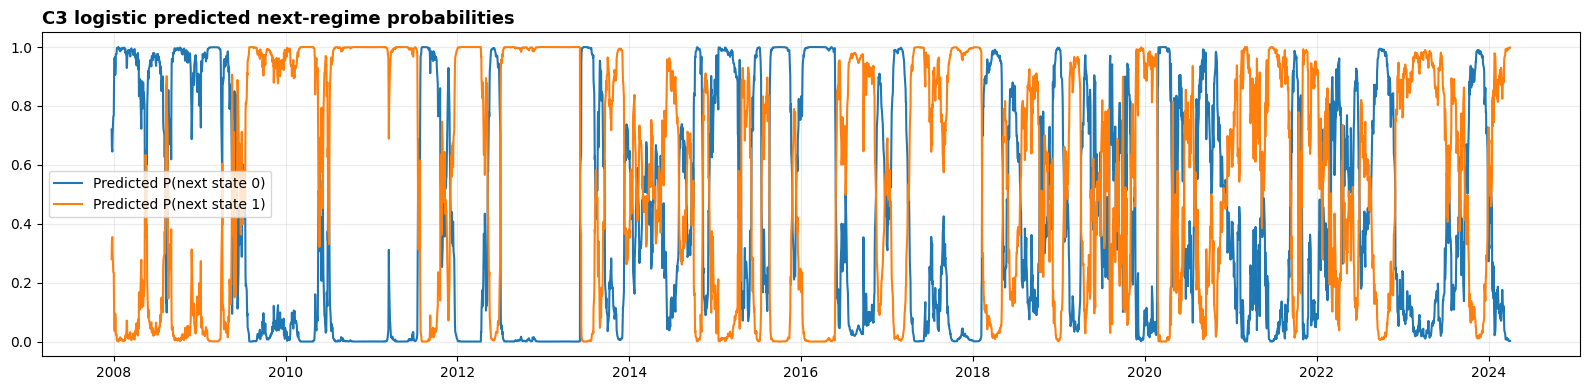


Objects created or updated:
next_state_prediction_panel
next_state_prediction_oos
next_state_prediction_summary
next_state_probability_bucket_summary
next_state_predicted_outcomes
selected_state_model_table
selected_next_state_probabilities
C3_SELECTED_MODEL


In [36]:
# =============================================================================
# CELL C3 - ROLLING LOGISTIC NEXT-REGIME PREDICTION
# =============================================================================

# Input: C2_state_panel and C2_KMEANS_FEATURES from the already-run KMeans regime cell.
# Output: selected_next_state_probabilities, used by Cell D allocation.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

title("C3 ROLLING LOGISTIC NEXT-REGIME PREDICTION")


def c2_forward_date_map(date_values, horizon_days):
    dates = pd.DatetimeIndex(pd.Series(date_values).dropna().unique()).sort_values()
    return {
        pd.Timestamp(dates[i]): pd.Timestamp(dates[i + int(horizon_days)])
        for i in range(0, max(0, len(dates) - int(horizon_days)))
    }


def c2_align_proba(model, X, k):
    raw_classes = list(model.classes_)
    raw_p = model.predict_proba(X)
    p = np.zeros((X.shape[0], int(k)))

    for j, cls in enumerate(raw_classes):
        cls = int(cls)
        if 0 <= cls < int(k):
            p[:, cls] = raw_p[:, j]

    row_sum = p.sum(axis=1)
    valid = row_sum > EPS
    p[valid] = p[valid] / row_sum[valid, None]
    p[~valid] = 1.0 / int(k)
    return p


def c2_prediction_quality(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    y = df["true_state"].astype(int)
    yhat = df["predicted_state"].astype(int)

    out = {
        "model": "logit",
        "n_obs": int(len(df)),
        "accuracy": float((y == yhat).mean()),
        "majority_class_accuracy": float(y.value_counts(normalize=True).max()),
        "mean_true_state": float(y.mean()),
        "mean_predicted_state": float(yhat.mean()),
    }

    for state_id in range(C2_K):
        actual = y.eq(state_id)
        predicted = yhat.eq(state_id)
        out[f"state_{state_id}_recall"] = float((actual & predicted).sum() / max(actual.sum(), 1))
        out[f"state_{state_id}_precision"] = float((actual & predicted).sum() / max(predicted.sum(), 1))

    return pd.DataFrame([out])


def c2_probability_bucket_summary(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    rows = []
    for state_id in range(C2_K):
        p_col = f"p_state_{state_id}"
        if p_col not in df.columns:
            continue

        g = df.copy()
        g["bucket"] = pd.qcut(g[p_col], 5, labels=False, duplicates="drop")
        bucket = (
            g.dropna(subset=["bucket"])
            .groupby("bucket", as_index=False)
            .agg(
                n_obs=("true_state", "count"),
                mean_probability=(p_col, "mean"),
                realized_state_share=("true_state", lambda x, sid=state_id: float((x == sid).mean())),
                mean_true_state=("true_state", "mean"),
            )
        )
        bucket["bucket"] = bucket["bucket"].astype(int) + 1
        bucket["probability_type"] = p_col
        rows.append(bucket)

    return pd.concat(rows, axis=0, ignore_index=True) if rows else pd.DataFrame()


C3_TARGET_HORIZON_DAYS = 21
C3_LOGIT_ROLLING_WINDOW_DAYS = 756
C3_LOGIT_MIN_DATES = 504
C3_LOGIT_C = 1.0
C3_SELECTED_MODEL = "logit"

labels_for_prediction = C2_state_panel[["date", "state"]].copy()
labels_for_prediction["date"] = pd.to_datetime(labels_for_prediction["date"])
labels_for_prediction = labels_for_prediction.sort_values("date").drop_duplicates("date", keep="last")

forward_date_map = c2_forward_date_map(labels_for_prediction["date"], C3_TARGET_HORIZON_DAYS)
labels_for_prediction = labels_for_prediction.set_index("date").sort_index()
labels_for_prediction["target_date"] = pd.Series(forward_date_map)
labels_for_prediction["target_state"] = labels_for_prediction["state"].shift(-int(C3_TARGET_HORIZON_DAYS))
labels_for_prediction = labels_for_prediction.dropna(subset=["target_date", "target_state"]).copy()
labels_for_prediction["target_state"] = labels_for_prediction["target_state"].astype(int)

prediction_features = regime_features_d[C2_KMEANS_FEATURES].copy()
prediction_features.index = pd.to_datetime(prediction_features.index)
prediction_features = prediction_features.sort_index().replace([np.inf, -np.inf], np.nan)

next_state_prediction_panel = prediction_features.join(
    labels_for_prediction[["target_date", "target_state"]],
    how="inner",
)
next_state_prediction_panel = next_state_prediction_panel.dropna(subset=["target_date", "target_state"]).copy()
next_state_prediction_panel["k"] = C2_K
next_state_prediction_panel = next_state_prediction_panel.rename_axis("date").reset_index()
next_state_prediction_panel["date"] = pd.to_datetime(next_state_prediction_panel["date"])
next_state_prediction_panel["target_date"] = pd.to_datetime(next_state_prediction_panel["target_date"])

print_table(
    "C3 next-regime prediction panel diagnostics",
    next_state_prediction_panel.groupby("k", as_index=False).agg(
        n_rows=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        first_target_date=("target_date", "min"),
        last_target_date=("target_date", "max"),
    ),
)

prediction_rows = []
dates = pd.DatetimeIndex(next_state_prediction_panel["date"].unique()).sort_values()

for i, d in enumerate(dates):
    d = pd.Timestamp(d)
    test_row = next_state_prediction_panel.loc[next_state_prediction_panel["date"].eq(d)].copy()
    if len(test_row) != 1:
        continue

    train = next_state_prediction_panel.loc[
        (next_state_prediction_panel["date"] < d)
        & (next_state_prediction_panel["target_date"] <= d)
    ].tail(int(C3_LOGIT_ROLLING_WINDOW_DAYS)).copy()

    if len(train) < int(C3_LOGIT_MIN_DATES):
        continue

    if train["target_state"].nunique() < 2:
        continue

    model = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l2",
            C=float(C3_LOGIT_C),
            max_iter=2000,
            class_weight="balanced",
            random_state=C2_RANDOM_STATE,
        )),
    ])

    X_train = train[C2_KMEANS_FEATURES]
    y_train = train["target_state"].astype(int)
    X_test = test_row[C2_KMEANS_FEATURES]

    model.fit(X_train, y_train)
    proba = c2_align_proba(model, X_test, C2_K)[0]
    pred_state = int(np.argmax(proba))

    row = {
        "date": d,
        "target_date": pd.Timestamp(test_row["target_date"].iloc[0]),
        "k": C2_K,
        "model": C3_SELECTED_MODEL,
        "true_state": int(test_row["target_state"].iloc[0]),
        "predicted_state": pred_state,
        "n_train": int(len(train)),
        "train_start": pd.Timestamp(train["date"].min()),
        "train_end": pd.Timestamp(train["date"].max()),
    }
    for state_id in range(C2_K):
        row[f"p_state_{state_id}"] = float(proba[state_id])
    prediction_rows.append(row)

    if i % C2_PROGRESS_EVERY_N_DATES == 0:
        print(f"C2 logit processed {i:,}/{len(dates):,}; date={d.date()}; predictions={len(prediction_rows):,}", flush=True)

next_state_prediction_oos = pd.DataFrame(prediction_rows)

if len(next_state_prediction_oos) == 0:
    raise RuntimeError("C2 logistic regression produced no next-regime predictions.")

next_state_prediction_summary = c2_prediction_quality(next_state_prediction_oos)
next_state_probability_bucket_summary = c2_probability_bucket_summary(next_state_prediction_oos)

next_state_predicted_outcomes = (
    next_state_prediction_oos
    .groupby(["model", "predicted_state"], as_index=False)
    .agg(
        n_obs=("true_state", "count"),
        realized_state0_share=("true_state", lambda x: float((x == 0).mean())),
        realized_state1_share=("true_state", lambda x: float((x == 1).mean())),
        mean_true_state=("true_state", "mean"),
    )
)

selected_state_model_table = next_state_prediction_summary.copy()
selected_next_state_probabilities = (
    next_state_prediction_oos
    .sort_values("date")
    .reset_index(drop=True)
)

print_table("C3 logit next-regime prediction summary", next_state_prediction_summary)
print_table("C3 logit probability bucket summary", next_state_probability_bucket_summary)
print_table("C3 realized states by predicted state", next_state_predicted_outcomes)
print_table("C3 selected next-state probabilities head", selected_next_state_probabilities.head(20))
print_table("C3 selected next-state probabilities tail", selected_next_state_probabilities.tail(20))

if C2_RUN_PLOTS:
    fig, ax = plt.subplots(figsize=(16, 4))
    plot_pred = selected_next_state_probabilities.copy()
    ax.plot(plot_pred["date"], plot_pred["p_state_0"], label="Predicted P(next state 0)")
    ax.plot(plot_pred["date"], plot_pred["p_state_1"], label="Predicted P(next state 1)")
    ax.set_title("C3 logistic predicted next-regime probabilities", loc="left", fontsize=13, fontweight="bold")
    ax.grid(True, alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

print("\nObjects created or updated:")
print("next_state_prediction_panel")
print("next_state_prediction_oos")
print("next_state_prediction_summary")
print("next_state_probability_bucket_summary")
print("next_state_predicted_outcomes")
print("selected_state_model_table")
print("selected_next_state_probabilities")
print("C3_SELECTED_MODEL")

## Cell D2 - Threshold allocation test

**Note on the saved run:** this cell was stopped while evaluating configuration 2 of 9. The output below shows the completed first configuration only.



D2 VALIDATE INPUTS

--------------------------------------------------------------------------------------------------------------
D2 input diagnostics
--------------------------------------------------------------------------------------------------------------
             item                                                 value
    forecast rows                                                  4243
       state rows                                                  4788
  rebalance dates                                                   203
  first rebalance                                   2007-12-24 00:00:00
   last rebalance                                   2024-04-01 00:00:00
     stock assets                                                   282
       good state                                                     1
risk-on threshold                                                   0.5
    moment method causal expanding equal-weight past good-state returns
       gamma gri

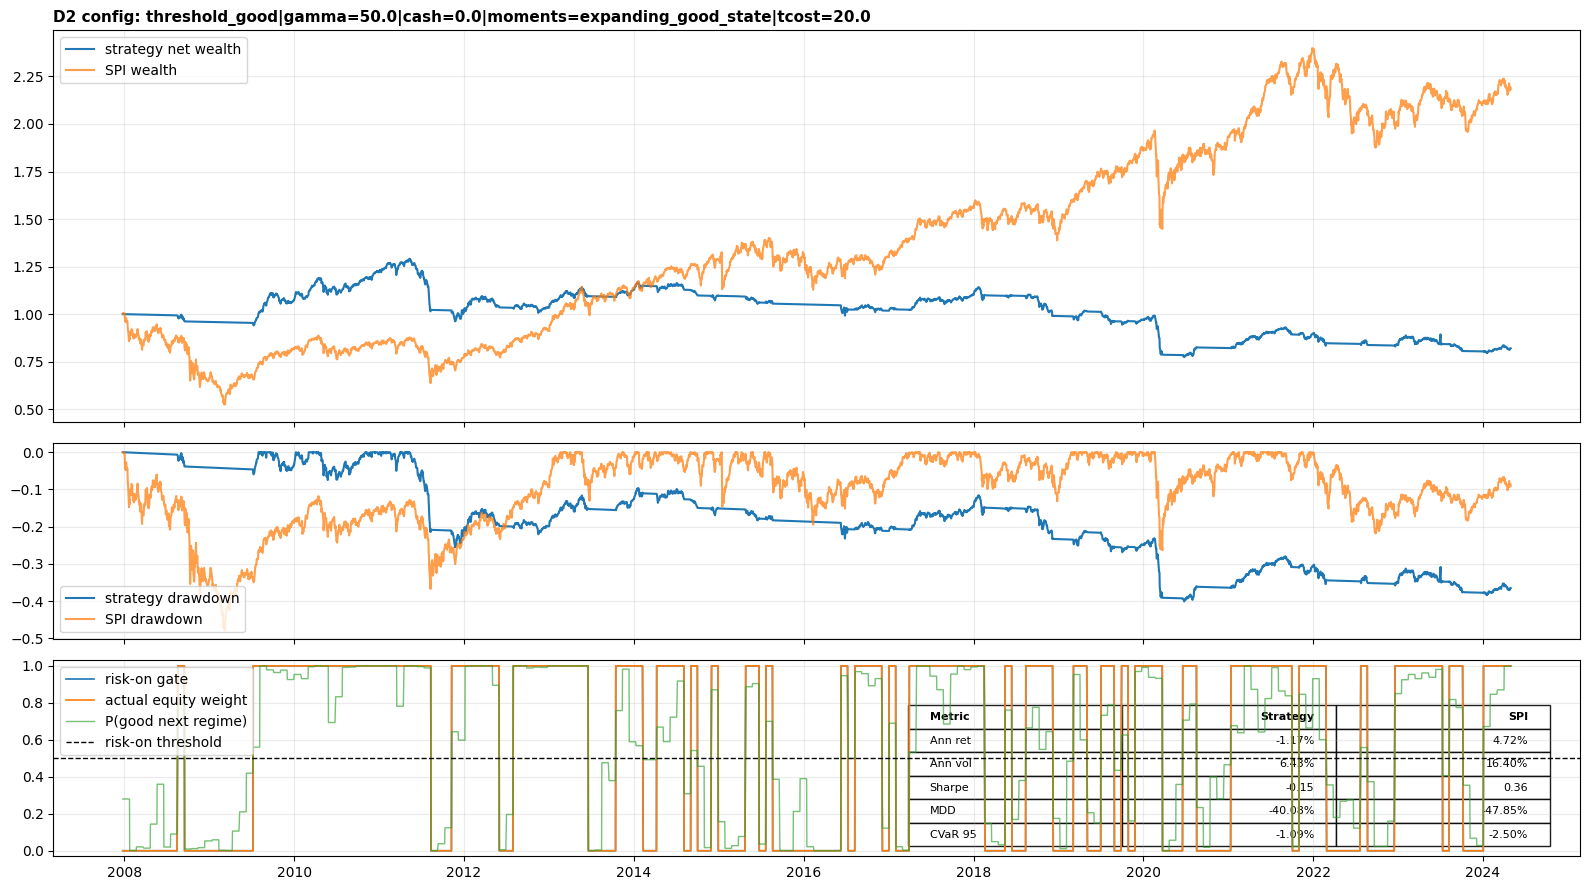


D2 START CONFIG 2/9: threshold_good|gamma=50.0|cash=0.02|moments=expanding_good_state|tcost=20.0


In [44]:
# =============================================================================
# CELL D2 - THRESHOLD GOOD-REGIME EQUITY GATE
# =============================================================================

# Rule:
# - C3 predicts next SPI regime probabilities.
# - If P(good) >= 0.50, switch risk-on and optimize stocks using good-state moments.
# - If P(good) < 0.50, hold 100% cash.
# - Equity moments are estimated only from past realized good-regime stock returns.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

D2_GOOD_STATE = 1
D2_GOOD_PROB_THRESHOLD = 0.50
D2_REBALANCE_EVERY_N_DATES = 21
D2_RISK_AVERSION_GRID = [50.0, 100.0, 200.0]
D2_CASH_HURDLE_PA_GRID = [0.00, 0.02, 0.05]
D2_TRANSACTION_COST_BPS = 20.0
D2_MIN_GOOD_STATE_OBS = 126
D2_MIN_ASSET_OBS = 60
D2_MAX_NAME_WEIGHT = 0.05
D2_COV_SHRINKAGE = 0.20
D2_MU_SHRINK_TO_ZERO = 0.50
D2_FIXED_COST_PA = 0.01
D2_PRINT_EACH_CONFIG = True
D2_PLOT_EACH_CONFIG = True
D2_PLOT_SELECTED = True

if "EPS" not in globals():
    EPS = 1e-12

D2_FIXED_COST_DAILY = (1.0 + D2_FIXED_COST_PA) ** (1.0 / 252.0) - 1.0
D2_TRANSACTION_COST_RATE = D2_TRANSACTION_COST_BPS / 10000.0

if "title" not in globals():
    def title(text):
        print("\n" + "=" * 110)
        print(text)
        print("=" * 110)

if "print_table" not in globals():
    def print_table(name, df, max_rows=None, index=False):
        print("\n" + "-" * 110)
        print(name)
        print("-" * 110)
        if df is None or len(df) == 0:
            print("EMPTY")
            return
        x = df.copy()
        if max_rows is not None:
            x = x.head(max_rows)
        print(x.to_string(index=index))


def d2_perf_summary(ret):
    r = pd.Series(ret).replace([np.inf, -np.inf], np.nan).dropna().astype(float)
    if len(r) == 0:
        return {
            "n_obs": 0,
            "ann_return": np.nan,
            "ann_vol": np.nan,
            "sharpe": np.nan,
            "max_drawdown": np.nan,
            "cvar_95_daily": np.nan,
            "cvar_99_daily": np.nan,
            "total_return": np.nan,
        }

    wealth = (1.0 + r).cumprod()
    ann_return = wealth.iloc[-1] ** (252.0 / len(r)) - 1.0
    ann_vol = r.std(ddof=1) * np.sqrt(252.0)
    sharpe = r.mean() / r.std(ddof=1) * np.sqrt(252.0) if r.std(ddof=1) > EPS else np.nan
    dd = wealth / wealth.cummax() - 1.0
    q05 = r.quantile(0.05)
    q01 = r.quantile(0.01)
    cvar_95 = r.loc[r <= q05].mean() if (r <= q05).any() else np.nan
    cvar_99 = r.loc[r <= q01].mean() if (r <= q01).any() else np.nan

    return {
        "n_obs": int(len(r)),
        "ann_return": float(ann_return),
        "ann_vol": float(ann_vol),
        "sharpe": float(sharpe),
        "max_drawdown": float(dd.min()),
        "cvar_95_daily": float(cvar_95),
        "cvar_99_daily": float(cvar_99),
        "total_return": float(wealth.iloc[-1] - 1.0),
    }


def d2_project_long_cash_cap(w):
    w = pd.Series(w).replace([np.inf, -np.inf], np.nan).fillna(0.0).clip(lower=0.0)
    w = w.clip(upper=D2_MAX_NAME_WEIGHT)
    total = float(w.sum())
    if total > 1.0:
        w = w / total
    return w


def d2_equal_weight_moments(X):
    X = X.replace([np.inf, -np.inf], np.nan).astype(float)
    mu = X.mean(axis=0, skipna=True)
    X0 = X.sub(mu, axis=1)
    cov = X0.cov(min_periods=D2_MIN_ASSET_OBS)
    cov = cov.reindex(index=X.columns, columns=X.columns).fillna(0.0)

    diag = np.diag(np.diag(cov.to_numpy(dtype=float)))
    cov_np = (1.0 - D2_COV_SHRINKAGE) * cov.to_numpy(dtype=float) + D2_COV_SHRINKAGE * diag
    return mu, pd.DataFrame(cov_np, index=X.columns, columns=X.columns)


def d2_good_state_moments(asof_date):
    hist_states = D2_state_by_date.loc[D2_state_by_date.index < pd.Timestamp(asof_date)].dropna().astype(int)
    good_dates = hist_states.index[hist_states.eq(int(D2_GOOD_STATE))]

    if len(good_dates) < D2_MIN_GOOD_STATE_OBS:
        return None

    X = stock_ret_wide.reindex(good_dates)
    obs = X.notna().sum(axis=0)
    assets = obs.loc[obs >= D2_MIN_ASSET_OBS].index.tolist()
    if len(assets) == 0:
        return None

    mu, cov = d2_equal_weight_moments(X[assets])
    mu = mu.dropna()
    assets = [a for a in assets if a in mu.index]
    if len(assets) == 0:
        return None

    mu = mu.reindex(assets)
    cov = cov.reindex(index=assets, columns=assets).fillna(0.0)
    cov_np = cov.to_numpy(dtype=float).copy()
    diag = np.diag(cov_np).copy()
    good_diag = np.isfinite(diag) & (diag > EPS)
    med = float(np.nanmedian(diag[good_diag])) if good_diag.any() else 1e-4
    diag = np.where(good_diag, diag, med)
    cov_np[np.diag_indices_from(cov_np)] = diag
    cov_np = 0.5 * (cov_np + cov_np.T) + 1e-6 * med * np.eye(len(assets))

    return {
        "assets": assets,
        "mu": mu,
        "cov": pd.DataFrame(cov_np, index=assets, columns=assets),
        "n_good_state_obs": int(len(good_dates)),
    }


def d2_cash_aware_weights(mu, cov, gamma, cash_hurdle_pa):
    cash_daily = (1.0 + float(cash_hurdle_pa)) ** (1.0 / 252.0) - 1.0
    mu_excess = (1.0 - D2_MU_SHRINK_TO_ZERO) * (mu.astype(float) - cash_daily)
    assets = mu_excess.index.tolist()
    cov_np = cov.reindex(index=assets, columns=assets).to_numpy(dtype=float).copy()

    try:
        raw = np.linalg.solve(cov_np, mu_excess.to_numpy(dtype=float)) / float(gamma)
    except Exception:
        raw = np.linalg.pinv(cov_np) @ mu_excess.to_numpy(dtype=float) / float(gamma)

    w = pd.Series(np.nan_to_num(raw, nan=0.0, posinf=0.0, neginf=0.0), index=assets)
    w = d2_project_long_cash_cap(w)
    return w.loc[w > 1e-12]


def d2_equity_budget_from_probability(p_good):
    if not np.isfinite(p_good):
        return 0.0
    return 1.0 if float(p_good) >= float(D2_GOOD_PROB_THRESHOLD) else 0.0


def d2_simulate(gamma, cash_hurdle_pa):
    path_rows, rebalance_rows = [], []
    current_w = pd.Series(dtype=float)

    for i, alloc_date in enumerate(D2_REBALANCE_DATES):
        alloc_date = pd.Timestamp(alloc_date)
        forecast_row = D2_forecast_by_date.loc[alloc_date]
        p_good = float(forecast_row.get(f"p_state_{D2_GOOD_STATE}", np.nan))
        equity_budget = d2_equity_budget_from_probability(p_good)
        predicted_good = bool(equity_budget > EPS)

        moment = None
        if equity_budget > EPS:
            moment = d2_good_state_moments(alloc_date)

        if equity_budget > EPS and moment is not None:
            target_w = d2_cash_aware_weights(moment["mu"], moment["cov"], gamma, cash_hurdle_pa)
            risky_sum = float(target_w.sum()) if len(target_w) else 0.0
            if risky_sum > equity_budget and risky_sum > EPS:
                target_w = target_w * (equity_budget / risky_sum)
            action = "risk_on" if float(target_w.sum()) > EPS else "cash"
            n_good_state_obs = int(moment["n_good_state_obs"])
        else:
            target_w = pd.Series(dtype=float)
            action = "cash"
            n_good_state_obs = 0 if moment is None else int(moment["n_good_state_obs"])

        next_alloc = D2_REBALANCE_DATES[i + 1] if i < len(D2_REBALANCE_DATES) - 1 else stock_ret_wide.index.max()
        holding_dates = stock_ret_wide.index[(stock_ret_wide.index > alloc_date) & (stock_ret_wide.index <= next_alloc)]

        union = current_w.index.union(target_w.index)
        trade_abs = float(np.abs(target_w.reindex(union).fillna(0.0) - current_w.reindex(union).fillna(0.0)).sum())
        tcost = D2_TRANSACTION_COST_RATE * trade_abs
        current_w = target_w.copy()

        equity_weight = float(current_w.sum()) if len(current_w) else 0.0
        cash_weight = float(max(0.0, 1.0 - equity_weight))
        w_arr = current_w.to_numpy(dtype=float)
        effective_n = float(1.0 / np.square(w_arr).sum()) if len(w_arr) and np.square(w_arr).sum() > EPS else 0.0

        rebalance_rows.append({
            "date": alloc_date,
            "action": action,
            "predicted_good": predicted_good,
            "p_good": p_good,
            "risk_on_gate": equity_budget,
            "gamma": gamma,
            "cash_hurdle_pa": cash_hurdle_pa,
            "n_good_state_obs": n_good_state_obs,
            "n_holdings": int((current_w > 0).sum()),
            "equity_weight": equity_weight,
            "cash_weight": cash_weight,
            "effective_n": effective_n,
            "stock_turnover": trade_abs,
            "transaction_cost": tcost,
        })

        first = True
        for ret_date in holding_dates:
            if len(current_w):
                r = stock_ret_wide.reindex(index=[ret_date], columns=current_w.index).iloc[0].replace([np.inf, -np.inf], np.nan).fillna(0.0).astype(float)
                stock_growth = current_w * (1.0 + r)
                gross_growth = max(0.0, 1.0 - float(current_w.sum())) + float(stock_growth.sum())
                gross_ret = gross_growth - 1.0
            else:
                stock_growth = pd.Series(dtype=float)
                gross_growth = 1.0
                gross_ret = 0.0

            cost_today = tcost if first else 0.0
            net_ret = gross_ret - cost_today - D2_FIXED_COST_DAILY
            equity_weight = float(current_w.sum()) if len(current_w) else 0.0
            cash_weight = float(max(0.0, 1.0 - equity_weight))

            path_rows.append({
                "date": pd.Timestamp(ret_date),
                "alloc_date": alloc_date,
                "action": action,
                "predicted_good": predicted_good,
                "p_good": p_good,
                "risk_on_gate": equity_budget,
                "gamma": gamma,
                "cash_hurdle_pa": cash_hurdle_pa,
                "gross_return": gross_ret,
                "net_return": net_ret,
                "transaction_cost": cost_today,
                "fixed_cost": D2_FIXED_COST_DAILY,
                "equity_weight": equity_weight,
                "cash_weight": cash_weight,
                "n_holdings": int((current_w > 0).sum()) if len(current_w) else 0,
                "stock_turnover": trade_abs if first else 0.0,
            })

            if len(current_w) and gross_growth > EPS:
                current_w = (stock_growth / gross_growth).loc[lambda s: s > 1e-12]

            first = False

    return pd.DataFrame(path_rows), pd.DataFrame(rebalance_rows)


def d2_path_summary(path):
    x = path.copy()
    x["date"] = pd.to_datetime(x["date"])
    mean_daily_turnover = float(x["stock_turnover"].mean()) if len(x) else np.nan
    return pd.DataFrame([{
        "sample": "oos",
        **d2_perf_summary(x["net_return"]),
        "mean_risk_on_gate": float(x["risk_on_gate"].mean()) if len(x) and "risk_on_gate" in x.columns else np.nan,
        "mean_equity_weight": float(x["equity_weight"].mean()) if len(x) else np.nan,
        "mean_cash_weight": float(x["cash_weight"].mean()) if len(x) else np.nan,
        "mean_n_holdings": float(x["n_holdings"].mean()) if len(x) else np.nan,
        "mean_daily_turnover": mean_daily_turnover,
        "ann_turnover": float(mean_daily_turnover * 252.0) if np.isfinite(mean_daily_turnover) else np.nan,
        "total_turnover": float(x["stock_turnover"].sum()) if len(x) else np.nan,
        "total_transaction_cost": float(x["transaction_cost"].sum()) if len(x) else np.nan,
        "total_fixed_cost": float(x["fixed_cost"].sum()) if len(x) else np.nan,
        "risk_on_day_share": float(x["predicted_good"].mean()) if len(x) else np.nan,
    }])


def d2_signal_exposure(rebalances):
    if len(rebalances) == 0:
        return pd.DataFrame()
    return (
        rebalances
        .groupby("action", as_index=False)
        .agg(
            n_rebalances=("date", "count"),
            mean_p_good=("p_good", "mean"),
            mean_risk_on_gate=("risk_on_gate", "mean"),
            mean_equity_weight=("equity_weight", "mean"),
            mean_cash_weight=("cash_weight", "mean"),
            mean_n_holdings=("n_holdings", "mean"),
            mean_n_good_state_obs=("n_good_state_obs", "mean"),
            mean_turnover=("stock_turnover", "mean"),
        )
    )


def d2_format_metric_value(metric, value):
    if not np.isfinite(value):
        return "n/a"
    if metric in {"ann_return", "ann_vol", "max_drawdown", "cvar_95_daily"}:
        return f"{100.0 * value:.2f}%"
    if metric == "sharpe":
        return f"{value:.2f}"
    return f"{value:.4f}"


def d2_plot_metric_table(ax, strategy_ret, spi_ret_same):
    strategy_stats = d2_perf_summary(strategy_ret)
    spi_stats = d2_perf_summary(spi_ret_same)
    rows = [
        ("Ann ret", "ann_return"),
        ("Ann vol", "ann_vol"),
        ("Sharpe", "sharpe"),
        ("MDD", "max_drawdown"),
        ("CVaR 95", "cvar_95_daily"),
    ]
    cell_text = [
        [label, d2_format_metric_value(key, strategy_stats.get(key, np.nan)), d2_format_metric_value(key, spi_stats.get(key, np.nan))]
        for label, key in rows
    ]
    table = ax.table(
        cellText=cell_text,
        colLabels=["Metric", "Strategy", "SPI"],
        cellLoc="right",
        colLoc="right",
        loc="lower right",
        bbox=[0.56, 0.05, 0.42, 0.72],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    for (row, col), cell in table.get_celld().items():
        cell.set_alpha(0.88)
        if row == 0:
            cell.set_text_props(weight="bold")
        if col == 0:
            cell.set_text_props(ha="left")
    return table


def d2_plot_path(path, strategy_id, title_prefix):
    if len(path) == 0:
        return

    x = path.copy().sort_values("date")
    x["date"] = pd.to_datetime(x["date"])
    x["strategy_wealth"] = (1.0 + x["net_return"].fillna(0.0)).cumprod()
    x["spi_return"] = spi_ret.reindex(pd.DatetimeIndex(x["date"])).fillna(0.0).to_numpy()
    x["spi_wealth"] = (1.0 + x["spi_return"]).cumprod()
    x["strategy_drawdown"] = x["strategy_wealth"] / x["strategy_wealth"].cummax() - 1.0
    x["spi_drawdown"] = x["spi_wealth"] / x["spi_wealth"].cummax() - 1.0

    fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
    axes[0].plot(x["date"], x["strategy_wealth"], label="strategy net wealth")
    axes[0].plot(x["date"], x["spi_wealth"], label="SPI wealth", alpha=0.75)
    axes[0].set_title(f"{title_prefix}: {strategy_id}", loc="left", fontsize=11, fontweight="bold")
    axes[0].grid(True, alpha=0.25)
    axes[0].legend(loc="upper left")

    axes[1].plot(x["date"], x["strategy_drawdown"], label="strategy drawdown")
    axes[1].plot(x["date"], x["spi_drawdown"], label="SPI drawdown", alpha=0.75)
    axes[1].grid(True, alpha=0.25)
    axes[1].legend(loc="lower left")

    axes[2].plot(x["date"], x["risk_on_gate"], label="risk-on gate", linewidth=1.2)
    axes[2].plot(x["date"], x["equity_weight"], label="actual equity weight", linewidth=1.2)
    axes[2].plot(x["date"], x["p_good"], label="P(good next regime)", alpha=0.65, linewidth=1.0)
    axes[2].axhline(D2_GOOD_PROB_THRESHOLD, color="black", linestyle="--", linewidth=1.0, label="risk-on threshold")
    axes[2].set_ylim(-0.03, 1.03)
    axes[2].grid(True, alpha=0.25)
    axes[2].legend(loc="upper left")
    d2_plot_metric_table(axes[2], x["net_return"], x["spi_return"])

    plt.tight_layout()
    plt.show()


title("D2 VALIDATE INPUTS")
for required in ["C2_state_panel", "selected_next_state_probabilities", "stock_ret_wide", "spi_ret"]:
    if required not in globals():
        raise RuntimeError(f"Run Cell C2 and Cell C3 first. Missing {required}.")

stock_ret_wide = stock_ret_wide.copy()
stock_ret_wide.index = pd.to_datetime(stock_ret_wide.index)
stock_ret_wide = stock_ret_wide.sort_index().replace([np.inf, -np.inf], np.nan)
stock_ret_wide.columns = stock_ret_wide.columns.astype(str)

spi_ret = pd.Series(spi_ret).copy()
spi_ret.index = pd.to_datetime(spi_ret.index)
spi_ret = spi_ret.sort_index().replace([np.inf, -np.inf], np.nan).astype(float)

D2_state_panel = C2_state_panel.copy()
D2_state_panel["date"] = pd.to_datetime(D2_state_panel["date"])
D2_state_panel = D2_state_panel.sort_values("date").drop_duplicates("date", keep="last")
D2_state_by_date = D2_state_panel.set_index("date")["state"].astype(int)

D2_forecast_panel = selected_next_state_probabilities.copy()
D2_forecast_panel["date"] = pd.to_datetime(D2_forecast_panel["date"])
D2_forecast_panel = D2_forecast_panel.sort_values("date").drop_duplicates("date", keep="last")
D2_forecast_by_date = D2_forecast_panel.set_index("date")

valid_dates = pd.DatetimeIndex(sorted(D2_forecast_by_date.index.intersection(stock_ret_wide.index)))
D2_REBALANCE_DATES = valid_dates[::D2_REBALANCE_EVERY_N_DATES]

D2_input_diagnostics = pd.DataFrame([
    {"item": "forecast rows", "value": len(D2_forecast_panel)},
    {"item": "state rows", "value": len(D2_state_panel)},
    {"item": "rebalance dates", "value": len(D2_REBALANCE_DATES)},
    {"item": "first rebalance", "value": D2_REBALANCE_DATES.min() if len(D2_REBALANCE_DATES) else pd.NaT},
    {"item": "last rebalance", "value": D2_REBALANCE_DATES.max() if len(D2_REBALANCE_DATES) else pd.NaT},
    {"item": "stock assets", "value": stock_ret_wide.shape[1]},
    {"item": "good state", "value": D2_GOOD_STATE},
    {"item": "risk-on threshold", "value": D2_GOOD_PROB_THRESHOLD},
    {"item": "moment method", "value": "causal expanding equal-weight past good-state returns"},
    {"item": "gamma grid", "value": str(D2_RISK_AVERSION_GRID)},
    {"item": "cash hurdle grid", "value": str(D2_CASH_HURDLE_PA_GRID)},
])
print_table("D2 input diagnostics", D2_input_diagnostics)

signal_diag = D2_forecast_panel.copy()
signal_diag["risk_on_gate"] = signal_diag[f"p_state_{D2_GOOD_STATE}"].apply(d2_equity_budget_from_probability)
signal_diag["predicted_good"] = signal_diag["risk_on_gate"].gt(EPS)
print_table("D2 C3 signal diagnostics", pd.DataFrame([{
    "n_forecasts": len(signal_diag),
    "risk_on_forecast_share": float(signal_diag["predicted_good"].mean()),
    "mean_p_good": float(signal_diag[f"p_state_{D2_GOOD_STATE}"].mean()),
    "median_p_good": float(signal_diag[f"p_state_{D2_GOOD_STATE}"].median()),
    "mean_risk_on_gate": float(signal_diag["risk_on_gate"].mean()),
    "median_risk_on_gate": float(signal_diag["risk_on_gate"].median()),
    "first_forecast": signal_diag["date"].min(),
    "last_forecast": signal_diag["date"].max(),
}]))

title("D2 RUN THRESHOLD GOOD-REGIME GRID")
D2_path_parts, D2_rebalance_parts, D2_summary_parts, D2_exposure_parts = [], [], [], []
total = len(D2_RISK_AVERSION_GRID) * len(D2_CASH_HURDLE_PA_GRID)
counter = 0

for gamma in D2_RISK_AVERSION_GRID:
    for cash_hurdle_pa in D2_CASH_HURDLE_PA_GRID:
        counter += 1
        sid = f"threshold_good|gamma={gamma}|cash={cash_hurdle_pa}|moments=expanding_good_state|tcost={D2_TRANSACTION_COST_BPS}"
        print("\n" + "=" * 110)
        print(f"D2 START CONFIG {counter}/{total}: {sid}")
        print("=" * 110, flush=True)

        path, rb = d2_simulate(float(gamma), float(cash_hurdle_pa))
        if len(path) == 0:
            print("No path produced.")
            continue

        path["strategy_id"] = sid
        rb["strategy_id"] = sid
        summ = d2_path_summary(path)
        summ.insert(0, "strategy_id", sid)
        summ.insert(1, "gamma", float(gamma))
        summ.insert(2, "cash_hurdle_pa", float(cash_hurdle_pa))
        exp = d2_signal_exposure(rb)
        if len(exp):
            exp.insert(0, "strategy_id", sid)

        D2_path_parts.append(path)
        D2_rebalance_parts.append(rb)
        D2_summary_parts.append(summ)
        D2_exposure_parts.append(exp)

        if D2_PRINT_EACH_CONFIG:
            compact_cols = [
                "strategy_id", "sample", "ann_return", "ann_vol", "sharpe", "max_drawdown",
                "cvar_95_daily", "ann_turnover", "mean_risk_on_gate", "mean_equity_weight", "mean_cash_weight", "risk_on_day_share",
            ]
            print_table("D2 finished config", summ[[c for c in compact_cols if c in summ.columns]])
            print_table("D2 config signal exposure", exp)

        if D2_PLOT_EACH_CONFIG:
            d2_plot_path(path, sid, "D2 config")

title("D2 FINAL OUTPUTS")
D_allocation_results_long = pd.concat(D2_path_parts, ignore_index=True) if D2_path_parts else pd.DataFrame()
D_allocation_rebalances_long = pd.concat(D2_rebalance_parts, ignore_index=True) if D2_rebalance_parts else pd.DataFrame()
D_allocation_strategy_summary = pd.concat(D2_summary_parts, ignore_index=True) if D2_summary_parts else pd.DataFrame()
D_signal_exposure_summary = pd.concat(D2_exposure_parts, ignore_index=True) if D2_exposure_parts else pd.DataFrame()
D_state_exposure_summary = D_signal_exposure_summary

if len(D_allocation_strategy_summary) == 0:
    raise RuntimeError("D2 produced no allocation paths. Check C3 forecast dates and good-state moment availability.")

summary_cols = [
    "strategy_id", "sample", "gamma", "cash_hurdle_pa", "ann_return", "ann_vol", "sharpe",
    "max_drawdown", "cvar_95_daily", "cvar_99_daily", "ann_turnover", "mean_equity_weight", "mean_cash_weight",
    "risk_on_day_share", "mean_risk_on_gate", "total_transaction_cost", "total_fixed_cost",
]
summary_view = D_allocation_strategy_summary.sort_values(["sharpe", "ann_return", "max_drawdown"], ascending=[False, False, False]).reset_index(drop=True)
print_table("D2 full OOS strategy summary", summary_view[[c for c in summary_cols if c in summary_view.columns]], max_rows=50)
print_table("D2 signal exposure summary", D_signal_exposure_summary, max_rows=100)

bench_rows = []
if len(D_allocation_results_long):
    tmp = D_allocation_results_long.copy()
    tmp["date"] = pd.to_datetime(tmp["date"])
    r = spi_ret.reindex(pd.DatetimeIndex(sorted(tmp["date"].unique()))).fillna(0.0)
    bench_rows.append({"benchmark": "SPI", "sample": "oos", **d2_perf_summary(r)})
D_spi_benchmark_summary = pd.DataFrame(bench_rows)
print_table("D2 SPI benchmark over same OOS dates", D_spi_benchmark_summary)

D_selected_strategy = summary_view.head(1).reset_index(drop=True)
D_SELECTED_STRATEGY_ID = D_selected_strategy.loc[0, "strategy_id"] if len(D_selected_strategy) else None
print_table("D2 selected threshold strategy by full OOS Sharpe", D_selected_strategy[[c for c in summary_cols if c in D_selected_strategy.columns]])

D_selected_path = D_allocation_results_long.loc[D_allocation_results_long["strategy_id"].eq(D_SELECTED_STRATEGY_ID)].copy()
D_selected_rebalances = D_allocation_rebalances_long.loc[D_allocation_rebalances_long["strategy_id"].eq(D_SELECTED_STRATEGY_ID)].copy()
print_table("D2 selected signal exposure", d2_signal_exposure(D_selected_rebalances))
print_table("D2 selected rebalances head", D_selected_rebalances.head(20))
print_table("D2 selected rebalances tail", D_selected_rebalances.tail(20))

if D2_PLOT_SELECTED and len(D_selected_path):
    d2_plot_path(D_selected_path, D_SELECTED_STRATEGY_ID, "D2 selected strategy")

print("\nObjects created or updated:")
print("D_allocation_results_long")
print("D_allocation_rebalances_long")
print("D_allocation_strategy_summary")
print("D_signal_exposure_summary")
print("D_state_exposure_summary")
print("D_spi_benchmark_summary")
print("D_selected_strategy")
print("D_SELECTED_STRATEGY_ID")
print("D_selected_path")
print("D_selected_rebalances")
